# Embryo cross-species radial-spectral visualization

This notebook is the only figure-generation entrypoint for the embryo analysis.
Run `workflow.py` first: the workflow owns SV, spectra, PCA-derived analysis,
clustering, temporal variation, and enrichment caches. This notebook reconstructs
the uncached plotting state, previews every panel, and then saves the combined
main and supplementary figures.


In [1]:
# Shared setup
import gc
import json
import sys
import textwrap
import warnings
from io import BytesIO
from pathlib import Path
from typing import Any

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "scripts" / "embryo_xspecies" / "config.py").exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        __package__ = "scripts.embryo_xspecies"
        break
else:
    raise RuntimeError("Run this notebook from the sonic-paper repository.")

import matplotlib
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from adjustText import adjust_text
from IPython.display import Image as IPythonImage
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox

from scripts.paper_utils import (
    FIGURE_DPI,
    FIGURE_WIDTH_IN,
    FONT_CONFIG,
    PAPER_CATEGORICAL,
    PAPER_COLORS,
    ensure_directories,
    paper_style,
    require_files,
)

from . import config as C
from . import embeddings, metrics, temporal, utils

warnings.filterwarnings("ignore", category=UserWarning, message=".*This figure includes Axes.*")

FONT_MIN = FONT_CONFIG["text"]
FONT_TICK = FONT_CONFIG["tick"]
FONT_TEXT = FONT_CONFIG["font"]
FONT_LABEL = FONT_CONFIG["label"]
FONT_TITLE = FONT_CONFIG["title"]
SCATTER_POINT_SIZE = 2.5
CATEGORY_COLORS = {
    "conserved dynamic": PAPER_COLORS["purple"],
    "mouse-specific dynamic": PAPER_COLORS["warm"],
    "human-specific dynamic": PAPER_COLORS["cool"],
}
MIXING_COLORS = {
    "species": PAPER_COLORS["cool"],
    "time": PAPER_COLORS["gold"],
    "expression": PAPER_COLORS["green"],
    "sv": PAPER_COLORS["pink"],
}
CLUSTER_COLORS = matplotlib.colors.ListedColormap(PAPER_CATEGORICAL[:5])
PATTERN_EXAMPLE_GENE = "Col11a1"
MAIN_FIGURE_QUERY = {
    "species": "mouse",
    "gene": "Col11a1",
    "section_id": "E14.5_E1S1",
}
MAIN_FIGURE_COMPARISONS = (
    {
        "figure_label": "1",
        "species": "mouse",
        "gene": "Sfrp2",
        "section_id": "E14.5_E2S1",
        "similarity_class": "close",
        "role": "close: related mesenchymal pattern",
    },
    {
        "figure_label": "2",
        "species": "human",
        "gene": "SFRP2",
        "section_id": "CS17_E1S9",
        "similarity_class": "close",
        "role": "close: conserved mesenchymal pattern",
    },
    {
        "figure_label": "3",
        "species": "mouse",
        "gene": "Apoa2",
        "section_id": "E14.5_E2S1",
        "similarity_class": "less similar",
        "role": "less similar: liver-marker pattern",
    },
    {
        "figure_label": "4",
        "species": "human",
        "gene": "APOA2",
        "section_id": "CS17_E1S9",
        "similarity_class": "less similar",
        "role": "less similar: human APOA2 ortholog",
    },
)
FIGURE_STYLE = paper_style(
    fonts=FONT_CONFIG,
    hide_spines=True,
    savefig_dpi=None,
    overrides={"xtick.major.width": 0.6, "ytick.major.width": 0.6},
)
ensure_directories(C.FIGURE_DIR)

## Preview and save helpers


In [2]:
def preview_axes(
    figure: plt.Figure,
    axes: list[plt.Axes],
    label: str,
    *,
    dpi: int = 160,
) -> None:
    """Display a tightly cropped notebook preview without writing a file."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    boxes = [
        axis.get_tightbbox(renderer)
        for axis in axes
        if axis.get_visible() and axis.get_tightbbox(renderer) is not None
    ]
    if not boxes:
        raise ValueError(f"No visible axes found for preview {label!r}.")
    bbox = Bbox.union(boxes).expanded(1.04, 1.08)
    bbox_inches = bbox.transformed(figure.dpi_scale_trans.inverted())
    buffer = BytesIO()
    figure.savefig(
        buffer,
        format="png",
        dpi=dpi,
        bbox_inches=bbox_inches,
        pad_inches=0.03,
        facecolor="white",
    )
    print(label)
    display(IPythonImage(data=buffer.getvalue()))


def save_figure(figure: plt.Figure, stem: str) -> None:
    """Save one publication PDF; panel previews remain notebook-only."""
    path = C.FIGURE_DIR / f"{stem}.pdf"
    figure.savefig(path, dpi=FIGURE_DPI)
    print("wrote", path.relative_to(C.PROJECT_ROOT))

## Load workflow caches and reconstruct plotting state


### Cache loading functions

In [3]:
def _load_spatial_record(
    points: pd.DataFrame, species: str, gene: str, section_id: str
) -> dict[str, Any]:
    """Load one normalized spatial map and its exact embedding coordinate."""
    point = points[
        points["species"].eq(species)
        & points["section_id"].eq(section_id)
        & points["gene"].eq(gene)
    ]
    if len(point) != 1:
        raise RuntimeError(
            f"Expected one embedding point for {gene} in {section_id}; found {len(point)}."
        )
    cfg = C.SPECIES_CONFIGS[species]
    sections, _, panel, _ = utils.load_prepared_sections(
        cfg,
        section_ids=[section_id],
        gene_panel=[gene],
        expression_mode=C.ANALYSIS_EXPRESSION_MODE,
        normalization_target_sum=C.ANALYSIS_NORMALIZATION_TARGET_SUM,
        include_domain_channels=False,
    )
    if panel != [gene]:
        raise RuntimeError(f"Spatial-map gene order changed for {section_id}.")
    table = sections[0].tables["bins_table"]
    rows = table.obs["array_row"].to_numpy(dtype=np.int64)
    cols = table.obs["array_col"].to_numpy(dtype=np.int64)
    rows -= rows.min()
    cols -= cols.min()
    image = np.zeros((int(rows.max()) + 1, int(cols.max()) + 1), dtype=np.float32)
    image[rows, cols] = np.asarray(table.X[:, 0].toarray()).ravel()
    if image.shape[1] > image.shape[0]:
        image = np.rot90(image)
    stage = str(point["timepoint"].iloc[0])
    cs_value = utils.carnegie_stage(species, timepoint=stage, day=float(point["day"].iloc[0]))
    record = {
        "species": species,
        "gene": gene,
        "stage": stage,
        "stage_index": int(point["stage_index"].iloc[0]),
        "cs_value": cs_value,
        "cs_label": stage if species == "human" else f"CS{cs_value:.1f}".removesuffix(".0"),
        "section_id": section_id,
        "image": image,
        **{column: float(point[column].iloc[0]) for column in metrics.PC_COLUMNS},
    }
    del sections, table
    gc.collect()
    return record


def _load_pattern_examples(points: pd.DataFrame) -> dict[str, Any]:
    """Load all representative maps and their exact gene-section PCA points."""
    mouse_gene = PATTERN_EXAMPLE_GENE
    human_genes = points.loc[
        points["species"].eq("human") & points["mouse_symbol"].eq(mouse_gene),
        "gene",
    ].drop_duplicates()
    if len(human_genes) != 1:
        raise RuntimeError(
            f"Expected one human ortholog for {mouse_gene}; found {human_genes.tolist()}."
        )
    genes = {"mouse": mouse_gene, "human": str(human_genes.iloc[0])}
    records: list[dict[str, Any]] = []
    for species, gene in genes.items():
        cfg = C.SPECIES_CONFIGS[species]
        for stage_index, stage in enumerate(cfg.KEPT_TIMEPOINTS):
            section_ids = cfg.REPRESENTATIVE_SECTIONS[stage]
            if len(section_ids) != 1:
                raise RuntimeError(
                    f"{species} {stage} must have exactly one representative section."
                )
            record = _load_spatial_record(points, species, gene, section_ids[0])
            if record["stage_index"] != stage_index:
                raise RuntimeError(f"Unexpected stage order for {section_ids[0]}.")
            records.append(record)
    return {"genes": genes, "records": records}


def _species_records(examples: dict[str, Any], species: str) -> list[dict[str, Any]]:
    return sorted(
        [record for record in examples["records"] if record["species"] == species],
        key=lambda record: record["stage_index"],
    )


def _load_similarity_examples(points: pd.DataFrame) -> dict[str, Any]:
    """Load the five examples fixed by the main-figure design."""
    query_config = MAIN_FIGURE_QUERY
    query = _load_spatial_record(
        points,
        query_config["species"],
        query_config["gene"],
        query_config["section_id"],
    )
    query["figure_label"] = "Q"
    records = []
    query_coordinate = np.array([query[column] for column in metrics.PC_COLUMNS])
    for example in MAIN_FIGURE_COMPARISONS:
        record = _load_spatial_record(
            points, example["species"], example["gene"], example["section_id"]
        )
        coordinate = np.array([record[column] for column in metrics.PC_COLUMNS])
        record.update(
            figure_label=example["figure_label"],
            role=example["role"],
            similarity_class=example["similarity_class"],
            distance=float(np.linalg.norm(coordinate - query_coordinate)),
        )
        records.append(record)
    return {"query": query, "records": records}


def _load_stage_spatial_maps(gene_pairs: pd.DataFrame) -> list[dict[str, Any]]:
    """Load normalized maps for each gene pair and representative stage."""
    records: list[dict[str, Any]] = []
    for species, cfg in C.SPECIES_CONFIGS.items():
        genes = gene_pairs[f"{species}_symbol"].astype(str).tolist()
        for stage in cfg.KEPT_TIMEPOINTS:
            section_ids = cfg.REPRESENTATIVE_SECTIONS[stage]
            if len(section_ids) != 1:
                raise RuntimeError(
                    f"{species} {stage} must configure exactly one representative section."
                )
            section_id = section_ids[0]
            sections, _, panel, _ = utils.load_prepared_sections(
                cfg,
                section_ids=[section_id],
                gene_panel=genes,
                expression_mode=C.ANALYSIS_EXPRESSION_MODE,
                normalization_target_sum=C.ANALYSIS_NORMALIZATION_TARGET_SUM,
                include_domain_channels=False,
            )
            if panel != genes:
                raise RuntimeError(f"{species} spatial-map gene order changed.")
            table = sections[0].tables["bins_table"]
            rows = table.obs["array_row"].to_numpy(dtype=np.int64)
            cols = table.obs["array_col"].to_numpy(dtype=np.int64)
            rows -= rows.min()
            cols -= cols.min()
            shape = (int(rows.max()) + 1, int(cols.max()) + 1)
            for gene_index, gene in enumerate(genes):
                image = np.zeros(shape, dtype=np.float32)
                image[rows, cols] = np.asarray(table.X[:, gene_index].toarray()).ravel()
                records.append(
                    {
                        "species": species,
                        "gene": gene,
                        "stage": stage,
                        "section_id": section_id,
                        "image": image,
                    }
                )
            del sections, table
            gc.collect()
    return records

In [4]:
# Fail before plotting if the workflow has not produced every required cache.
required = [
    metrics.RESULT_DIR / "manifest.json",
    metrics.RESULT_DIR / "cluster_summary.csv",
    metrics.RESULT_DIR / "cluster_go_enrichment.csv.gz",
    metrics.RESULT_DIR / "gene_stage_cluster_membership.csv.gz",
    metrics.RESULT_DIR / "local_mixing_by_section.csv",
    temporal.RESULT_DIR / "temporal_gene_statistics.csv.gz",
    temporal.RESULT_DIR / "ortholog_temporal_conservation.csv.gz",
    temporal.RESULT_DIR / "temporal_go_enrichment.csv.gz",
    temporal.RESULT_DIR / "selected_genes.csv",
    temporal.RESULT_DIR / "metrics.csv.gz",
    temporal.RESULT_DIR / "summary.csv",
    temporal.RESULT_DIR / "go_enrichment.csv.gz",
]
require_files(
    required,
    label="embryo workflow caches; run python -m scripts.embryo_xspecies.workflow",
)

# PCA coordinates remain intentionally uncached. Refit the deterministic joint
# embedding and annotate it from the metric caches.
EMBEDDING = embeddings.load_spectra_and_fit_joint_embedding()
POINTS = metrics.embedding_points(EMBEDDING)
CENTRES = pd.read_csv(metrics.RESULT_DIR / "cluster_summary.csv")
centre_coordinates = CENTRES[metrics.PC_COLUMNS].to_numpy(np.float32)
point_coordinates = POINTS[metrics.PC_COLUMNS].to_numpy(np.float32)
cluster_ids = CENTRES["cluster"].to_numpy(int)
assigned = np.empty(len(POINTS), dtype=int)
for start in range(0, len(POINTS), 100_000):
    stop = min(start + 100_000, len(POINTS))
    distance = np.square(
        point_coordinates[start:stop, None, :] - centre_coordinates[None, :, :]
    ).sum(axis=2)
    assigned[start:stop] = cluster_ids[distance.argmin(axis=1)]
POINTS["cluster"] = assigned
del point_coordinates, centre_coordinates, assigned
gc.collect()

# Load per-cluster GO enrichment results
CLUSTER_ENRICHMENT = pd.read_csv(metrics.RESULT_DIR / "cluster_go_enrichment.csv.gz")
# Keep top 4 FDR-significant, simplified, non-background-generic GO terms per cluster.
CLUSTER_TERMS = metrics.select_go_terms(
    CLUSTER_ENRICHMENT,
    group_columns=["species", "cluster"],
    fdr_column="global_qvalue",
)
MIXING_BY_SECTION = pd.read_csv(metrics.RESULT_DIR / "local_mixing_by_section.csv")
MIXING_SUMMARY = metrics.summarize_local_mixing(MIXING_BY_SECTION)
GENE_EXAMPLES = _load_pattern_examples(POINTS)
SIMILARITY_EXAMPLES = _load_similarity_examples(POINTS)

TEMPORAL_STATISTICS = pd.read_csv(temporal.RESULT_DIR / "temporal_gene_statistics.csv.gz")
MOUSE_TEMPORAL = TEMPORAL_STATISTICS[TEMPORAL_STATISTICS["species"].eq("mouse")]
HUMAN_TEMPORAL = TEMPORAL_STATISTICS[TEMPORAL_STATISTICS["species"].eq("human")]
ORTHOLOG_TEMPORAL = pd.read_csv(temporal.RESULT_DIR / "ortholog_temporal_conservation.csv.gz")

# Load per-species GO enrichment results for the temporal-dynamics gene sets.
TEMPORAL_ENRICHMENT = pd.read_csv(temporal.RESULT_DIR / "temporal_go_enrichment.csv.gz")
# Keep top 4 FDR-significant, simplified, non-background-generic GO terms per cluster.
TEMPORAL_TERMS = metrics.select_go_terms(
    TEMPORAL_ENRICHMENT,
    group_columns=["query_group"],
    fdr_column="p_adjust",
)
SELECTED_GENES = pd.read_csv(temporal.RESULT_DIR / "selected_genes.csv")
STAGE_TRANSITIONS = pd.read_csv(temporal.RESULT_DIR / "metrics.csv.gz")
STAGE_TRANSITION_SUMMARY = pd.read_csv(temporal.RESULT_DIR / "summary.csv")
STAGE_TRANSITION_ENRICHMENT = pd.read_csv(temporal.RESULT_DIR / "go_enrichment.csv.gz")
STAGE_TRANSITION_ENRICHMENT[["species", "current_stage"]] = STAGE_TRANSITION_ENRICHMENT[
    "query_group"
].str.split("|", expand=True)
trajectory_genes = set(SELECTED_GENES["mouse_symbol"].astype(str))
TRAJECTORIES = (
    POINTS[POINTS["mouse_symbol"].isin(trajectory_genes)]
    .groupby(
        ["species", "mouse_symbol", "human_symbol", "timepoint"],
        as_index=False,
    )
    .agg(
        stage_index=("stage_index", "first"),
        **{column: (column, "median") for column in metrics.PC_COLUMNS},
    )
    .sort_values(["species", "mouse_symbol", "stage_index"])
)
TEMPORAL_MANIFEST = json.loads((temporal.RESULT_DIR / "manifest.json").read_text())[
    "global_variation"
]

print(f"loaded {len(POINTS):,} gene-section patterns")

loaded 529,092 gene-section patterns


### Shared visualization functions

In [5]:
def _embedding_plot_context(
    points: pd.DataFrame, similarity_examples: dict[str, Any]
) -> dict[str, Any]:
    """Prepare deterministic limits and point samples shared by main panels."""
    x_limits = tuple(points["PC1"].quantile([0.001, 0.999]).to_numpy(float))
    y_limits = list(points["PC2"].quantile([0.001, 0.999]).to_numpy(float))
    highlighted_y = [similarity_examples["query"]["PC2"]] + [
        record["PC2"] for record in similarity_examples["records"]
    ]
    y_limits[0] = min(y_limits[0], min(highlighted_y))
    y_limits[1] = max(y_limits[1], max(highlighted_y))
    y_margin = 0.04 * (y_limits[1] - y_limits[0])
    rng = np.random.default_rng(0)
    plot_sample = points.iloc[
        rng.choice(len(points), size=min(120_000, len(points)), replace=False)
    ].copy()
    return {
        "x_limits": x_limits,
        "y_limits": (y_limits[0] - y_margin, y_limits[1] + y_margin),
        "plot_sample": plot_sample,
        "mini_sample": plot_sample.sample(n=min(12_000, len(plot_sample)), random_state=0),
    }


def _scale_bar_length_um(image_width_bins: int) -> int:
    target = 0.28 * image_width_bins * C.BIN_SIZE_UM
    choices = (100, 200, 500, 1_000, 2_000, 5_000)
    return max((value for value in choices if value <= target), default=choices[0])


def plot_spatial_gene_rows(
    figure: plt.Figure,
    slot: Any,
    gene_pairs: pd.DataFrame,
    spatial_maps: list[dict[str, Any]],
) -> list[plt.Axes]:
    """Plot mouse and human stage series for one or more ortholog pairs."""
    spatial_cmaps = {
        "mouse": plt.get_cmap("Reds"),
        "human": plt.get_cmap("Blues"),
    }
    rows = slot.subgridspec(len(gene_pairs), 1, hspace=0.10)
    by_key = {
        (record["species"], record["gene"], record["stage"]): record for record in spatial_maps
    }
    axes: list[plt.Axes] = []
    for row_index, candidate in enumerate(gene_pairs.itertuples()):
        genes = {
            "mouse": str(candidate.mouse_symbol),
            "human": str(candidate.human_symbol),
        }
        species_records: dict[str, list[tuple[str, np.ndarray]]] = {}
        display_totals = {}
        section_gap = 0.035
        for species, gene in genes.items():
            records = []
            for stage in C.SPECIES_CONFIGS[species].KEPT_TIMEPOINTS:
                image = by_key[(species, gene, stage)]["image"]
                if image.shape[1] > image.shape[0]:
                    image = np.rot90(image)
                records.append((stage, image))
            species_records[species] = records
            display_totals[species] = sum(
                image.shape[1] / image.shape[0] for _, image in records
            ) + section_gap * (len(records) - 1)

        positive = np.concatenate(
            [image[image > 0] for records in species_records.values() for _, image in records]
        )
        norm = matplotlib.colors.Normalize(vmin=0, vmax=float(np.quantile(positive, 0.99)))
        supporting_term = (
            "No specific GO term; involved in intra-Golgi vesicle transport"
            if pd.isna(candidate.pathway_terms)
            else str(candidate.pathway_terms).split("; ", maxsplit=1)[0]
        )

        # Preserve each section's physical aspect ratio while sharing row width.
        row_box = rows[row_index, 0].get_position(figure)
        map_left = row_box.x0 - 0.015 * row_box.width
        colorbar_gap = 0.005 * row_box.width
        colorbar_width = 0.006 * row_box.width
        species_gap_width = 0.06 * row_box.width
        right_padding = 0.015 * row_box.width
        map_width = (
            row_box.x1
            - right_padding
            - map_left
            - species_gap_width
            - 2 * (colorbar_gap + colorbar_width)
        )
        total_display_width = sum(display_totals.values())
        mouse_width = map_width * display_totals["mouse"] / total_display_width
        mouse_colorbar_left = map_left + mouse_width + colorbar_gap
        human_left = mouse_colorbar_left + colorbar_width + species_gap_width
        species_positions = {
            "mouse": (map_left, mouse_width, mouse_colorbar_left),
            "human": (
                human_left,
                map_width - mouse_width,
                human_left + map_width - mouse_width + colorbar_gap,
            ),
        }

        for species in ("mouse", "human"):
            left, width, colorbar_left = species_positions[species]
            spatial_ax = figure.add_axes([left, row_box.y0, width, row_box.height])
            axes.append(spatial_ax)
            x_position = 0.0
            for stage, image in species_records[species]:
                display_width = image.shape[1] / image.shape[0]
                spatial_ax.imshow(
                    image,
                    origin="lower",
                    interpolation="nearest",
                    cmap=spatial_cmaps[species],
                    norm=norm,
                    rasterized=True,
                    extent=(x_position, x_position + display_width, 0, 1),
                )
                # The strip rescales each image to unit height; convert the
                # native bin coordinates before adding its physical scale bar.
                _add_scale_bar(
                    spatial_ax,
                    image.shape[1],
                    _scale_bar_length_um(image.shape[1]),
                    x_offset=x_position,
                    x_scale=1 / image.shape[0],
                )
                if row_index == 0:
                    spatial_ax.text(
                        x_position + display_width / 2,
                        1.04,
                        stage,
                        transform=spatial_ax.get_xaxis_transform(),
                        fontsize=FONT_MIN,
                        ha="center",
                        va="bottom",
                        color="#333333",
                        clip_on=False,
                    )
                x_position += display_width + section_gap

            spatial_ax.set(xlim=(0, x_position - section_gap), ylim=(0, 1))
            spatial_ax.set_aspect("equal")
            spatial_ax.axis("off")
            header_y = 1.22 if row_index == 0 else 1.05
            spatial_ax.text(
                0,
                header_y,
                genes[species],
                transform=spatial_ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=FONT_LABEL,
                fontstyle="italic",
                color=spatial_cmaps[species](0.8),
                clip_on=False,
            )
            if species == "mouse":
                spatial_ax.text(
                    1,
                    header_y,
                    supporting_term,
                    transform=spatial_ax.transAxes,
                    ha="right",
                    va="bottom",
                    fontsize=FONT_MIN,
                    color="#555555",
                    clip_on=False,
                )
            displayed_height = min(
                row_box.height,
                width * figure.get_figwidth() / (display_totals[species] * figure.get_figheight()),
            )
            cax = figure.add_axes(
                [
                    colorbar_left,
                    row_box.y0 + (row_box.height - displayed_height) / 2,
                    colorbar_width,
                    displayed_height,
                ]
            )
            axes.append(cax)
            colorbar = figure.colorbar(
                matplotlib.cm.ScalarMappable(norm=norm, cmap=spatial_cmaps[species]),
                cax=cax,
            )
            colorbar.set_ticks([0, norm.vmax], labels=["0", "P99"])
            colorbar.outline.set_linewidth(0.4)
            colorbar.ax.tick_params(labelsize=FONT_MIN, width=0.4, length=1.5, pad=1)
    return axes

## Main figure: embedding space structure + examples

Row 1 summarizes embedding organization and local mixing. Row 2 links exact
representative-slide coordinates to mouse spatial dynamics. Row 3 uses one
gene-section pattern to retrieve nearest genes within and across species.


### Panel A: de novo spatial-pattern clusters


In [6]:
def plot_embedding_clusters_panel(
    figure: plt.Figure,
    slot: Any,
    points: pd.DataFrame,
    centres: pd.DataFrame,
    variance_ratio: np.ndarray,
    context: dict[str, Any],
) -> list[plt.Axes]:
    """Plot de novo spatial-pattern clusters in the joint PCA space."""
    ax = figure.add_subplot(slot)

    for cluster, group in context["plot_sample"].groupby("cluster", sort=True):
        ax.scatter(
            group["PC1"],
            group["PC2"],
            s=SCATTER_POINT_SIZE,
            alpha=0.24,
            color=CLUSTER_COLORS((int(cluster) - 1) % CLUSTER_COLORS.N),
            linewidth=0,
            rasterized=True,
        )

    ax.scatter(
        centres["PC1"],
        centres["PC2"],
        s=32,
        color="white",
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    # Manually stagger labels while keeping each label aligned to its centre in PC1.
    label_y_offsets = {
        1: 8.5,
        2: -8,
        3: 6,
        4: -8,
        5: 3,  # lower the lipid cluster label
    }

    for row in centres.itertuples():
        cluster = int(row.cluster)
        y_offset = label_y_offsets.get(cluster, 0)

        ax.text(
            float(row.PC1),
            float(row.PC2) + y_offset,
            textwrap.fill(row.functional_label, width=17),
            fontsize=FONT_TEXT,
            ha="center",
            va="center",
            color=CLUSTER_COLORS((cluster - 1) % CLUSTER_COLORS.N),
            bbox={
                "facecolor": "white",
                "alpha": 0.9,
                "edgecolor": "none",
                "pad": 1,
            },
            zorder=4,
        )

    ax.set(
        xlabel=f"PC1 ({100 * variance_ratio[0]:.1f}% variance)",
        ylabel=f"PC2 ({100 * variance_ratio[1]:.1f}% variance)",
        xlim=context["x_limits"],
        ylim=context["y_limits"],
    )
    ax.set_box_aspect(1)
    ax.tick_params(pad=1)

    return [ax]

De novo spatial-pattern clusters


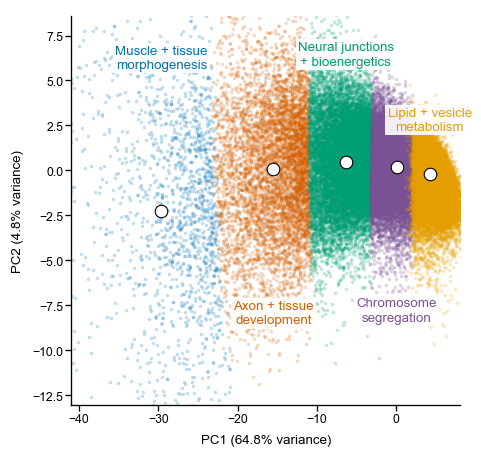

In [7]:
with plt.rc_context(FIGURE_STYLE):
    panel_a_preview = plt.figure(figsize=(3.2, 3.0))
    slot = panel_a_preview.add_gridspec(1, 1, left=0.18, right=0.97, bottom=0.16, top=0.97)[0, 0]
    panel_a_axes = plot_embedding_clusters_panel(
        panel_a_preview,
        slot,
        POINTS,
        CENTRES,
        EMBEDDING["pca"].explained_variance_ratio_,
        _embedding_plot_context(POINTS, SIMILARITY_EXAMPLES),
    )
    preview_axes(panel_a_preview, panel_a_axes, "De novo spatial-pattern clusters")
    plt.close(panel_a_preview)

### Panel B: density, species-stage, SV, and expression


In [8]:
def plot_embedding_annotations_panel(
    figure: plt.Figure,
    slot: Any,
    points: pd.DataFrame,
    context: dict[str, Any],
) -> list[plt.Axes]:
    """Plot density, stage, spatial-variability, and expression overlays."""
    first_axis = len(figure.axes)
    grid = slot.subgridspec(2, 2, hspace=0.25, wspace=0.16)
    axes = []

    # Add a second row of subgridspecs to hold the colorbars for each of the four panels.
    colorbar_slots = []
    for row in range(2):
        for column in range(2):
            cell = grid[row, column].subgridspec(
                2,
                1,
                height_ratios=[1, 0.1],
                hspace=0.06,
            )
            axes.append(figure.add_subplot(cell[0, 0]))
            colorbar_slots.append(cell[1, 0])

    density_ax, stage_ax, sv_ax, expression_ax = axes

    # Gene density.
    density_image = density_ax.hexbin(
        points["PC1"],
        points["PC2"],
        gridsize=(54, 48),
        mincnt=3,
        cmap="Greys",
        bins="log",
        rasterized=True,
    )
    density_ax.set_title("Gene density", loc="left", pad=1)

    cax = figure.add_subplot(colorbar_slots[0])
    colorbar = figure.colorbar(
        density_image,
        cax=cax,
        orientation="horizontal",
    )
    colorbar.ax.tick_params(
        labelsize=FONT_MIN,
        width=0.35,
        length=1.5,
        pad=1,
    )
    colorbar.outline.set_linewidth(0.5)

    # Species and Carnegie stage.
    mini_sample = context["mini_sample"]
    stage_colormaps = {
        species: matplotlib.colors.LinearSegmentedColormap.from_list(
            f"{species}_stage",
            plt.get_cmap(name)(np.linspace(0.35, 0.9, 256)),
        )
        for species, name in {
            "mouse": "Reds",
            "human": "Blues",
        }.items()
    }

    # Map mouse embryonic days to Carnegie Stages for consistent cross-species coloring.
    mouse_mask = mini_sample["species"].eq("mouse").to_numpy()
    carnegie_values = np.empty(len(mini_sample), dtype=float)
    carnegie_values[mouse_mask] = utils.mouse_e_to_carnegie(
        mini_sample.loc[mouse_mask, "day"].to_numpy(float)
    )
    carnegie_values[~mouse_mask] = mini_sample.loc[
        ~mouse_mask,
        "timepoint",
    ].map(utils.human_label_to_carnegie)

    cs_norm = matplotlib.colors.Normalize(
        vmin=np.floor(carnegie_values.min()),
        vmax=np.ceil(carnegie_values.max()),
    )

    point_colors = np.empty((len(mini_sample), 4), dtype=float)
    for species, cmap in stage_colormaps.items():
        mask = mini_sample["species"].eq(species).to_numpy()
        point_colors[mask] = cmap(cs_norm(carnegie_values[mask]))

    stage_ax.scatter(
        mini_sample["PC1"],
        mini_sample["PC2"],
        s=5,
        color=point_colors,
        alpha=0.25,
        linewidth=0,
        rasterized=True,
    )

    # Add a compact species legend using solid species-colored markers.
    legend_handles = [
        matplotlib.lines.Line2D(
            [],
            [],
            marker="o",
            linestyle="None",
            markersize=3.8,
            markerfacecolor=stage_colormaps["mouse"](0.82),
            markeredgecolor="none",
            label="Mouse",
        ),
        matplotlib.lines.Line2D(
            [],
            [],
            marker="o",
            linestyle="None",
            markersize=3.8,
            markerfacecolor=stage_colormaps["human"](0.82),
            markeredgecolor="none",
            label="Human",
        ),
    ]
    stage_ax.legend(
        handles=legend_handles,
        loc="lower right",
        frameon=False,
        fontsize=FONT_MIN,
        handletextpad=0.3,
        labelspacing=0.15,
        borderpad=0.2,
        handlelength=0.8,
    )

    cs_ticks = [cs_norm.vmin, 20, cs_norm.vmax]
    stage_colorbars = colorbar_slots[1].subgridspec(
        2,
        1,
        hspace=0.35,
    )

    for index, species in enumerate(("mouse", "human")):
        cax = figure.add_subplot(stage_colorbars[index, 0])
        colorbar = figure.colorbar(
            matplotlib.cm.ScalarMappable(
                norm=cs_norm,
                cmap=stage_colormaps[species],
            ),
            cax=cax,
            orientation="horizontal",
        )
        colorbar.set_ticks(cs_ticks)
        colorbar.ax.tick_params(
            labelsize=FONT_MIN,
            width=0.35,
            length=1.5,
            pad=0.5,
            labelbottom=species == "human",
        )

        if species == "human":
            colorbar.set_ticklabels(
                [
                    f"CS{cs_ticks[0]:g}",
                    f"CS{cs_ticks[1]:g}",
                    f"CS{cs_ticks[2]:g}",
                ]
            )

        colorbar.outline.set_linewidth(0.5)

    stage_ax.set_title("Species + stage", loc="left", pad=1)

    # Spatial variability and expression percentiles.
    for ax, colorbar_slot, column, title, cmap in [
        (
            sv_ax,
            colorbar_slots[2],
            "sv_percentile",
            "SV percentile",
            "cividis",
        ),
        (
            expression_ax,
            colorbar_slots[3],
            "expression_percentile",
            "Expression percentile",
            "viridis",
        ),
    ]:
        colored = mini_sample.sort_values(column)
        image = ax.scatter(
            colored["PC1"],
            colored["PC2"],
            c=colored[column],
            cmap=cmap,
            vmin=0,
            vmax=1,
            s=5,
            alpha=0.25,
            linewidth=0,
            rasterized=True,
        )
        ax.set_title(title, loc="left", pad=1)

        cax = figure.add_subplot(colorbar_slot)
        colorbar = figure.colorbar(
            image,
            cax=cax,
            orientation="horizontal",
        )
        colorbar.set_ticks([0, 1])
        colorbar.set_ticklabels(["Lower (0%)", "Higher (100%)"])
        ticklabels = colorbar.ax.get_xticklabels()
        ticklabels[0].set_ha("left")
        ticklabels[1].set_ha("right")

        colorbar.ax.tick_params(
            labelsize=FONT_MIN,
            width=0.35,
            length=1.5,
            pad=1,
        )
        colorbar.outline.set_linewidth(0.5)

    for ax in axes:
        ax.set(
            xlim=context["x_limits"],
            ylim=context["y_limits"],
            xticks=[],
            yticks=[],
        )
        ax.tick_params(length=0)

    return figure.axes[first_axis:]

Embedding annotations


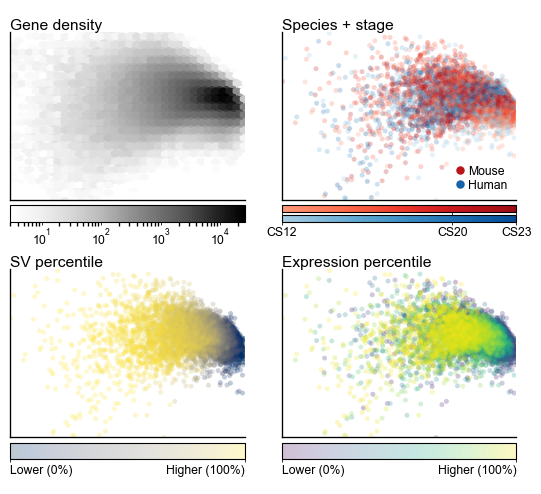

In [9]:
with plt.rc_context(FIGURE_STYLE):
    panel_b_preview = plt.figure(figsize=(3.4, 3.0))
    slot = panel_b_preview.add_gridspec(1, 1, left=0.05, right=0.98, bottom=0.08, top=0.97)[0, 0]
    panel_b_axes = plot_embedding_annotations_panel(
        panel_b_preview,
        slot,
        POINTS,
        _embedding_plot_context(POINTS, SIMILARITY_EXAMPLES),
    )
    preview_axes(panel_b_preview, panel_b_axes, "Embedding annotations")
    plt.close(panel_b_preview)

### Panel C: local mixing distributions


In [10]:
def plot_local_mixing_panel(
    figure: plt.Figure,
    slot: Any,
    by_section: pd.DataFrame,
    summary: pd.DataFrame,
) -> list[plt.Axes]:
    """Plot section-level distributions of corrected TV mixing."""
    ax = figure.add_subplot(slot)
    factors = ["species", "time", "expression", "sv"]
    rng = np.random.default_rng(0)
    for index, factor in enumerate(factors):
        values = by_section.loc[by_section["factor"].eq(factor), "mixing_score"].to_numpy(float)
        violin = ax.violinplot(
            values,
            positions=[index],
            orientation="horizontal",
            widths=0.7,
            showextrema=False,
        )
        for body in violin["bodies"]:
            body.set_facecolor(MIXING_COLORS[factor])
            body.set_edgecolor("none")
            body.set_alpha(0.28)
        ax.scatter(
            values,
            index + rng.uniform(-0.15, 0.15, len(values)),
            s=5,
            color=MIXING_COLORS[factor],
            alpha=0.4,
            linewidth=0,
            rasterized=True,
        )

    ax.set(
        xlabel="Corrected total-variation\nmixing score",
        yticks=np.arange(len(factors)),
        yticklabels=[
            textwrap.fill(f"{label}\n(n={by_section['factor'].eq(factor).sum():,})", width=10)
            for factor, label in zip(
                factors,
                ("Species", "Time", "Expression quintile", "SV quintile"),
                strict=True,
            )
        ],
        xlim=(0, 1.01),
    )
    ax.invert_yaxis()
    ax.text(
        0.5,
        0.02,
        "0 clustered  |  1 mixed",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=FONT_MIN,
        color="#555555",
    )
    return [ax]

Local mixing distributions


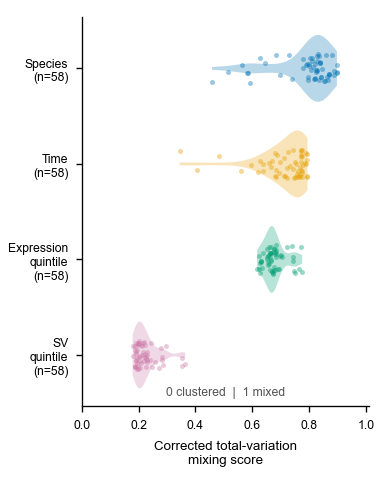

In [11]:
with plt.rc_context(FIGURE_STYLE):
    panel_c_preview = plt.figure(figsize=(2.6, 3.0))
    slot = panel_c_preview.add_gridspec(1, 1, left=0.28, right=0.97, bottom=0.16, top=0.97)[0, 0]
    panel_c_axes = plot_local_mixing_panel(panel_c_preview, slot, MIXING_BY_SECTION, MIXING_SUMMARY)
    preview_axes(panel_c_preview, panel_c_axes, "Local mixing distributions")
    plt.close(panel_c_preview)

### Panels D and E: embedding space exploration 

In [12]:
def _sample_label(record: dict[str, Any], *, include_species: bool = False) -> str:
    """Format a section's developmental stage and slide identifier."""
    label = f"{record['cs_label']}\n{record['section_id']}"
    return f"{record['species']} {label}" if include_species else label


def _add_scale_bar(
    ax: plt.Axes,
    image_width_bins: int,
    length_um: int,
    *,
    x_offset: float = 0,
    x_scale: float = 1,
) -> None:
    """Draw a physical scale bar in native or rescaled bin coordinates."""
    length = length_um / C.BIN_SIZE_UM * x_scale
    x_start = x_offset + 0.06 * image_width_bins * x_scale
    transform = ax.get_xaxis_transform()
    line = ax.plot(
        [x_start, x_start + length],
        [0.055, 0.055],
        color="black",
        linewidth=1.1,
        solid_capstyle="butt",
        transform=transform,
        clip_on=False,
        zorder=5,
    )[0]
    line.set_path_effects(
        [path_effects.Stroke(linewidth=2.1, foreground="white"), path_effects.Normal()]
    )
    label = ax.text(
        x_start + length / 2,
        0.08,
        f"{length_um / 1000:g} mm",
        transform=transform,
        ha="center",
        va="bottom",
        fontsize=FONT_MIN,
        color="black",
        zorder=5,
    )
    label.set_path_effects([path_effects.withStroke(linewidth=1.5, foreground="white")])


def _plot_embedding_background(
    ax: plt.Axes,
    sample: pd.DataFrame,
    x_limits: tuple[float, float],
    y_limits: tuple[float, float],
) -> None:
    ax.hexbin(
        sample["PC1"],
        sample["PC2"],
        gridsize=(54, 48),
        mincnt=3,
        cmap="Greys",
        bins="log",
        alpha=0.25,
        rasterized=True,
    )
    ax.set(xlim=x_limits, ylim=y_limits)

#### Panel D: mouse temporal trajectory and spatial maps


In [13]:
def _draw_exact_trajectory(
    ax: plt.Axes,
    records: list[dict[str, Any]],
) -> None:
    """Draw the mouse temporal trajectory and manually offset stage labels."""
    colors = plt.get_cmap("Reds")(np.linspace(0.42, 0.9, len(records)))
    coordinates = np.array([[record["PC1"], record["PC2"]] for record in records], dtype=float)
    for index in range(len(records) - 1):
        ax.annotate(
            "",
            xy=coordinates[index + 1],
            xytext=coordinates[index],
            arrowprops={
                "arrowstyle": "-|>",
                "color": colors[index + 1],
                "linewidth": 1.0,
                "mutation_scale": 6,
                "shrinkA": 2,
                "shrinkB": 2,
            },
            zorder=2,
        )
    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        c=colors,
        marker="o",
        s=24,
        edgecolor="white",
        linewidth=0.5,
        zorder=3,
    )
    labels = [
        ax.text(
            x_value,
            y_value,
            record["cs_label"],
            fontsize=FONT_TEXT,
            ha="center",
            va="center",
            color=color,
            zorder=4,
        )
        for record, color, (x_value, y_value) in zip(records, colors, coordinates, strict=True)
    ]
    for label in labels:
        label.set_path_effects([path_effects.withStroke(linewidth=1.3, foreground="white")])
    adjust_text(
        labels,
        ax=ax,
        x=coordinates[:, 0],
        y=coordinates[:, 1],
        force_explode=(1, 1),
        force_static=(1, 1),
        expand_text=(1.2, 1.2),
    )


def _plot_spatial_series(figure: plt.Figure, slot: Any, records: list[dict[str, Any]]) -> None:
    """Plot mouse sections at a common physical scale and expression scale."""
    cmap = plt.get_cmap("Reds")
    stage_colors = cmap(np.linspace(0.42, 0.9, len(records)))

    positive = np.concatenate([record["image"][record["image"] > 0] for record in records])
    vmax = float(np.quantile(positive, 0.99)) if positive.size else 1.0
    norm = matplotlib.colors.Normalize(vmin=0, vmax=max(vmax, 1e-12))

    widths = [record["image"].shape[1] for record in records]
    max_height = max(record["image"].shape[0] for record in records)

    # Keep only the spatial-map columns; the colorbar is anchored to the last map.
    maps = slot.subgridspec(
        1,
        len(records),
        width_ratios=widths,
        wspace=0.05,
    )

    image_axes = []

    for index, (record, color) in enumerate(zip(records, stage_colors, strict=True)):
        ax = figure.add_subplot(maps[0, index])
        image_axes.append(ax)

        height, width = record["image"].shape
        ax.imshow(
            record["image"],
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
            origin="upper",
            extent=(0, width, 0, height),
            rasterized=True,
        )
        ax.set(
            xlim=(0, width),
            ylim=(0, max_height),
            aspect="equal",
            facecolor=cmap(0),
        )
        ax.set_title(
            _sample_label(record),
            fontsize=FONT_TEXT,
            color=color,
            pad=1,
            y=1.05,
            linespacing=1.0,
        )

        if index == len(records) - 1:
            _add_scale_bar(ax, width, 1_000)

        ax.axis("off")

    right_ax = image_axes[-1]
    colorbar_ax = right_ax.inset_axes(
        [1.06, 0.0, 0.08, 1.0],
        transform=right_ax.transAxes,
    )

    colorbar = figure.colorbar(
        matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap),
        cax=colorbar_ax,
    )
    colorbar.ax.set_title("Log1p", fontsize=FONT_TEXT, pad=2)
    colorbar.ax.tick_params(
        labelsize=FONT_MIN,
        width=0.4,
        length=1.5,
        pad=1,
    )
    colorbar.outline.set_linewidth(0.5)


def plot_mouse_trajectory_panel(
    figure: plt.Figure,
    slot: Any,
    examples: dict[str, Any],
    context: dict[str, Any],
) -> list[plt.Axes]:
    """Plot the mouse gene trajectory beside equal-scale spatial maps."""
    first_axis = len(figure.axes)
    row = slot.subgridspec(1, 2, width_ratios=[1.15, 2.85], wspace=0.1)
    trajectory_ax = figure.add_subplot(row[0, 0])
    records = _species_records(examples, "mouse")

    # Left: trajectory in the joint PCA embedding with stage labels and arrows.
    _plot_embedding_background(
        trajectory_ax,
        context["plot_sample"],
        context["x_limits"],
        context["y_limits"],
    )
    _draw_exact_trajectory(trajectory_ax, records)
    gene = examples["genes"]["mouse"]
    trajectory_ax.set_title(rf"Temporal trajectory: $\mathit{{{gene}}}$ (mouse)", loc="left", pad=2)
    trajectory_ax.set_box_aspect(1)
    trajectory_ax.axis("off")

    # Right: spatial maps of the same gene in each mouse section at a common scale.
    _plot_spatial_series(figure, row[0, 1], records)

    return figure.axes[first_axis:]

Mouse trajectory and spatial maps


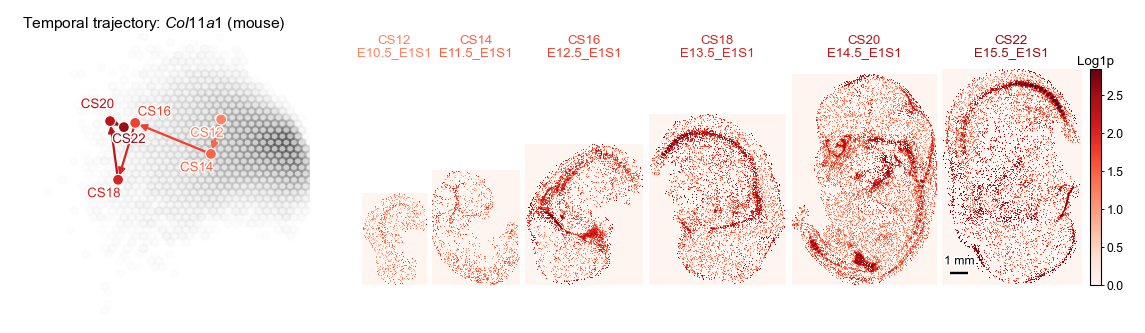

In [14]:
with plt.rc_context(FIGURE_STYLE):
    panel_d_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 2))
    slot = panel_d_preview.add_gridspec(1, 1, left=0.065, right=0.975, bottom=0.05, top=0.95)[0, 0]
    panel_d_axes = plot_mouse_trajectory_panel(
        panel_d_preview,
        slot,
        GENE_EXAMPLES,
        _embedding_plot_context(POINTS, SIMILARITY_EXAMPLES),
    )
    preview_axes(panel_d_preview, panel_d_axes, "Mouse trajectory and spatial maps")
    plt.close(panel_d_preview)

#### Panel E: query-based cross-species pattern retrieval


In [15]:
NEAREST_PATTERNS = embeddings.query_nearest_gene_stages(
    query_gene=MAIN_FIGURE_QUERY["gene"],
    query_species=MAIN_FIGURE_QUERY["species"],
    query_section_id=MAIN_FIGURE_QUERY["section_id"],
    embedding=EMBEDDING,
    top_n=30,
)
display(NEAREST_PATTERNS)

,query_species,query_gene,query_stage,query_section_id,rank,target_species,target_gene,target_stage,target_section_id,distance
0,mouse,Col11a1,E14.5,E14.5_E1S1,1,mouse,Sfrp2,E14.5,E14.5_E2S1,0.417440
1,mouse,Col11a1,E14.5,E14.5_E1S1,2,mouse,Igfbpl1,E12.5,E12.5_E1S2,0.610907
2,mouse,Col11a1,E14.5,E14.5_E1S1,3,mouse,Ptn,E14.5,E14.5_E1S3,0.620849
3,mouse,Col11a1,E14.5,E14.5_E1S1,4,mouse,Igf1,E12.5,E12.5_E1S5,0.792635
4,mouse,Col11a1,E14.5,E14.5_E1S1,5,mouse,Sparc,E12.5,E12.5_E1S2,0.836108
5,mouse,Col11a1,E14.5,E14.5_E1S1,6,mouse,Rpsa,E13.5,E13.5_E1S3,0.852060
6,mouse,Col11a1,E14.5,E14.5_E1S1,7,mouse,Rps24,E14.5,E14.5_E1S5,0.891711
7,mouse,Col11a1,E14.5,E14.5_E1S1,8,mouse,Tuba1a,E12.5,E12.5_E1S1,0.965719
8,mouse,Col11a1,E14.5,E14.5_E1S1,9,mouse,Cldn11,E15.5,E15.5_E2S1,0.984848
9,mouse,Col11a1,E14.5,E14.5_E1S1,10,mouse,Irx1,E11.5,E11.5_E1S1,0.994726


In [16]:
def _plot_similarity_retrieval(
    ax: plt.Axes,
    sample: pd.DataFrame,
    examples: dict[str, Any],
    x_limits: tuple[float, float],
    y_limits: tuple[float, float],
) -> None:
    """Plot labeled query and retrieval points in the joint PCA space."""
    _plot_embedding_background(
        ax,
        sample,
        x_limits,
        y_limits,
    )

    query = examples["query"]
    records = [query, *examples["records"]]
    colors = {
        "Q": "black",
        "1": "#9055A2",
        "2": "#6C49B8",
        "3": "#881600",
        "4": "#49010F",
    }
    offsets = {
        "Q": (-15, -20),
        "1": (45, 24),
        "2": (-10, 15),
        "3": (5, 15),
        "4": (10, -30),
    }

    for record in records:
        label = record["figure_label"]
        color = colors[label]
        marker = "*" if label == "Q" else ("o" if record["species"] == "mouse" else "^")

        ax.scatter(
            record["PC1"],
            record["PC2"],
            s=120 if label == "Q" else 20,
            marker=marker,
            facecolor="white" if label != "Q" else "none",
            edgecolor=color,
            linewidth=0.8,
            zorder=3,
        )

        ax.annotate(
            (
                ("Query\n" if label == "Q" else "")
                + rf"$\mathit{{{record['gene']}}}$ ({record['species']})"
                + f"\n{record['section_id']}"
            ),
            xy=(record["PC1"], record["PC2"]),
            xytext=offsets[label],
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=FONT_TEXT,
            color=color,
            zorder=4,
            bbox={
                "facecolor": "white",
                "edgecolor": "black" if label == "Q" else "none",
                "linewidth": 0.5,
                "alpha": 0.8,
                "pad": 0.7,
            },
            arrowprops={
                "arrowstyle": "-",
                "color": color,
                "linewidth": 0.5,
                "alpha": 0.8,
                "shrinkA": 2,
                "shrinkB": 3,
            },
        )

    ax.set_box_aspect(1)
    ax.axis("off")


def _plot_spatial_examples_equal(figure: plt.Figure, slot: Any, examples: dict[str, Any]) -> None:
    """Plot spatial heatmap for selected examples in equal size."""
    records = examples["records"]
    aspect_ratios = [record["image"].shape[1] / record["image"].shape[0] for record in records]

    maps = slot.subgridspec(
        1,
        len(records),
        width_ratios=[*aspect_ratios],
        wspace=0.05,
    )
    image_axes = []

    for index, record in enumerate(records):
        map_ax = figure.add_subplot(maps[0, index])
        image_axes.append(map_ax)

        image = np.asarray(record["image"], dtype=float)
        positive = image[image > 0]
        vmax = float(np.quantile(positive, 0.99)) if positive.size else 1.0
        display = np.clip(image / max(vmax, 1e-12), 0, 1)

        cmap = plt.get_cmap("Reds" if record["species"] == "mouse" else "Blues")
        map_ax.imshow(
            display,
            cmap=cmap,
            vmin=0,
            vmax=1,
            interpolation="nearest",
            origin="upper",
            rasterized=True,
        )

        map_ax.set_title(
            rf"$\mathit{{{record['gene']}}}$ ({record['species']})"
            f"\n{record['cs_label']} | {record['section_id']}\n"
            f"\nd={record['distance']:.2f}",
            fontsize=FONT_TEXT,
            pad=2,
            y=1.05,
            linespacing=1.0,
        )
        map_ax.text(
            0.5,
            -0.05,
            ("Mesenchymal", "Mesenchymal", "Liver", "Liver")[index],
            transform=map_ax.transAxes,
            fontsize=FONT_TEXT,
            ha="center",
            va="top",
        )
        _add_scale_bar(
            map_ax,
            image.shape[1],
            _scale_bar_length_um(image.shape[1]),
        )
        map_ax.axis("off")

    right_ax = image_axes[-1]
    norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

    for offset, (_species, cmap_name) in enumerate((("mouse", "Reds"), ("human", "Blues"))):
        colorbar_ax = right_ax.inset_axes(
            [1.06 + offset * 0.08, 0.0, 0.05, 1.0],
            transform=right_ax.transAxes,
        )

        colorbar = figure.colorbar(
            matplotlib.cm.ScalarMappable(
                norm=norm,
                cmap=cmap_name,
            ),
            cax=colorbar_ax,
        )
        if offset == 0:
            colorbar.ax.set_title("Normalized\nexpression", fontsize=FONT_TEXT, pad=2, y=1.02)
            colorbar.set_ticks([0, 1], labels=["", ""])
        else:
            colorbar.set_ticks([0, 1], labels=["Low", "High"])
            colorbar.ax.tick_params(
                labelsize=FONT_TEXT,
                width=0.2,
                length=1.5,
                pad=1,
                left=offset == 0,
                right=offset == 1,
                labelleft=offset == 0,
                labelright=offset == 1,
            )
        colorbar.outline.set_linewidth(0.5)


def plot_similarity_panel(
    figure: plt.Figure,
    slot: Any,
    examples: dict[str, Any],
    context: dict[str, Any],
) -> list[plt.Axes]:
    """Plot the retrieval embedding beside aligned spatial maps."""
    first_axis = len(figure.axes)
    row = slot.subgridspec(
        1,
        2,
        width_ratios=[1.25, 2.75],
        wspace=0.10,
    )

    retrieval_ax = figure.add_subplot(row[0, 0])
    _plot_similarity_retrieval(
        retrieval_ax,
        context["plot_sample"],
        examples,
        context["x_limits"],
        context["y_limits"],
    )
    retrieval_ax.set_title(
        "PCA distance reflects pattern similarity",
        loc="left",
        pad=2,
    )
    _plot_spatial_examples_equal(figure, row[0, 1], examples)

    return figure.axes[first_axis:]

Query-based pattern retrieval


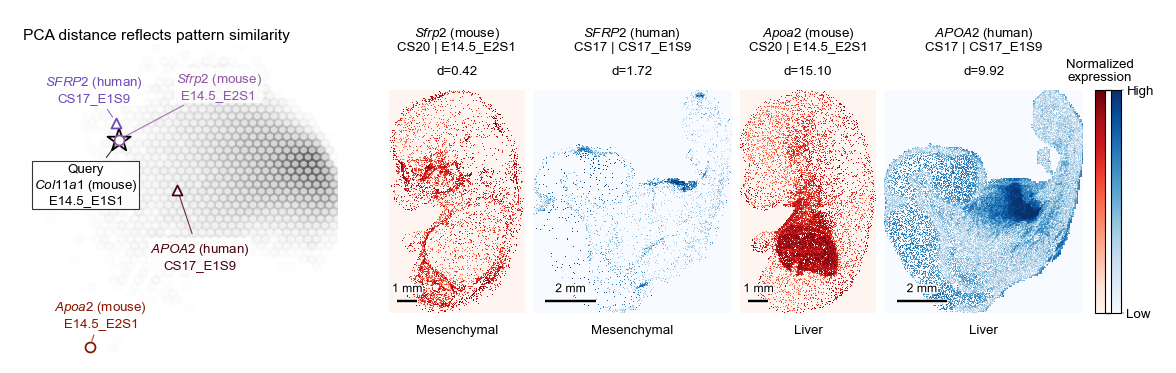

In [17]:
with plt.rc_context(FIGURE_STYLE):
    panel_e_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 2.5))
    slot = panel_e_preview.add_gridspec(1, 1, left=0.065, right=0.975, bottom=0.05, top=0.95)[0, 0]
    panel_e_axes = plot_similarity_panel(
        panel_e_preview,
        slot,
        SIMILARITY_EXAMPLES,
        _embedding_plot_context(POINTS, SIMILARITY_EXAMPLES),
    )
    preview_axes(panel_e_preview, panel_e_axes, "Query-based pattern retrieval")
    plt.close(panel_e_preview)

### Save the combined main figure


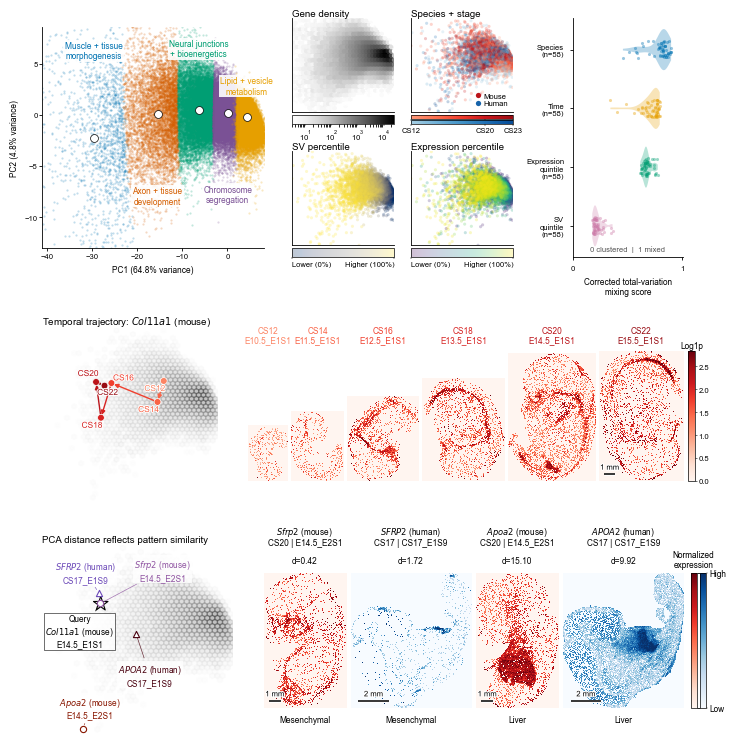

In [18]:
def build_embedding_main_figure() -> plt.Figure:
    """Assemble the three-row embedding-space main figure."""
    with plt.rc_context(FIGURE_STYLE):
        figure = plt.figure(figsize=(FIGURE_WIDTH_IN, 205 / 25.4))
        layout = figure.add_gridspec(
            4,
            1,
            height_ratios=[1.15, 0.1, 1, 1],
            left=0.05,
            right=0.93,
            bottom=0.05,
            top=0.95,
            hspace=0.10,
        )
        top = layout[0, 0].subgridspec(1, 4, width_ratios=[1.2, 1.2, 0.02, 0.6], wspace=0.2)
        context = _embedding_plot_context(POINTS, SIMILARITY_EXAMPLES)

        # First row
        plot_embedding_clusters_panel(
            figure,
            top[0, 0],
            POINTS,
            CENTRES,
            EMBEDDING["pca"].explained_variance_ratio_,
            context,
        )
        plot_embedding_annotations_panel(figure, top[0, 1], POINTS, context)
        plot_local_mixing_panel(figure, top[0, 3], MIXING_BY_SECTION, MIXING_SUMMARY)
        # Second row sits empty to allow for a larger gap above the trajectory row.
        plot_mouse_trajectory_panel(figure, layout[2, 0], GENE_EXAMPLES, context)
        plot_similarity_panel(figure, layout[3, 0], SIMILARITY_EXAMPLES, context)
        return figure


build_embedding_main_figure()

In [19]:
figure = build_embedding_main_figure()
save_figure(figure, "embedding")
plt.close(figure)

wrote figures/embryo_xspecies/embedding.pdf


## Supplement: cluster GO programs


### Preview selected GO terms for each cluster and species

In [20]:
CLUSTER_TERMS.head()

,query_group,source,native,name,display_name,p_value,p_raw,p_adjust,q_value,significant,...,hit_genes,semantic_simplified,semantic_simplify_cutoff,semantic_simplify_measure,method,species,cluster,global_qvalue,fold_enrichment,term_universe_fraction
0,human:1,GO:BP,GO:0060537,muscle tissue development,Muscle tissue development,3.208180e-10,4.405327e-13,3.208180e-10,2.475098e-10,True,...,ACTA1/ACTC1/ACTN2/ALDH1A2/CENPF/COL11A1/COL3A1...,True,0.7,Wang,clusterProfiler,human,1,1.304911e-10,4.475817,0.031776
1,human:1,GO:BP,GO:0002181,cytoplasmic translation,Cytoplasmic translation,2.178971e-09,3.740080e-12,2.178971e-09,1.681068e-09,True,...,RPL10/RPL11/RPL13A/RPL23/RPL26/RPL3/RPL31/RPL3...,True,0.7,Wang,clusterProfiler,human,1,8.809466e-10,4.909412,0.024443
2,human:1,GO:BP,GO:0006936,muscle contraction,Muscle contraction,2.136105e-08,4.399805e-11,2.136105e-08,1.647997e-08,True,...,ACTA1/ACTA2/ACTC1/ATP2A2/CALM2/CRYAB/DES/DSP/E...,True,0.7,Wang,clusterProfiler,human,1,7.022900e-09,5.227614,0.019554
3,human:1,GO:BP,GO:0030239,myofibril assembly,Myofibril assembly,1.373478e-07,4.243497e-10,1.373478e-07,1.059633e-07,True,...,ACTA1/ACTC1/ACTG1/ACTN2/KRT19/MYL9/MYOM1/NEBL/...,True,0.7,Wang,clusterProfiler,human,1,5.457919e-08,10.598095,0.005032
4,human:2,GO:BP,GO:0002181,cytoplasmic translation,Cytoplasmic translation,1.234485e-27,3.189059e-31,1.234485e-27,8.553393e-28,True,...,EEF2/EIF4A1/EIF4A2/FAU/HNRNPU/PABPC1/PKM/RACK1...,True,0.7,Wang,clusterProfiler,human,2,6.234611e-27,4.065446,0.024443


In [21]:
def _cluster_enrichment_figure(
    enrichment: pd.DataFrame,
    centres: pd.DataFrame,
) -> plt.Figure:
    """Compare mouse and human GO enrichment within each cluster."""
    clusters = centres["cluster"].astype(int).tolist()
    labels = centres.set_index("cluster")["functional_label"]
    figure, axes = plt.subplots(
        len(clusters),
        2,
        figsize=(FIGURE_WIDTH_IN, 165 / 25.4),
        squeeze=False,
    )
    # Each row is a cluster, with mouse GO terms on the left and human GO terms on the right.
    for row, cluster in enumerate(clusters):
        color = CLUSTER_COLORS((cluster - 1) % CLUSTER_COLORS.N)
        for column, species in enumerate(("mouse", "human")):
            ax = axes[row, column]
            # Sort terms by significance (per-species FDR).
            group = enrichment[
                enrichment["cluster"].eq(cluster) & enrichment["species"].eq(species)
            ].sort_values("global_qvalue", ascending=False)

            # Lollipop plot
            y = np.arange(len(group))
            strength = -np.log10(np.maximum(group["global_qvalue"], 1e-300))
            ax.hlines(y, 0, strength, color=color, alpha=0.32, linewidth=1)
            ax.scatter(strength, y, s=20, color=color, edgecolor="white", linewidth=0.5)
            for x_value, y_value, fold in zip(strength, y, group["fold_enrichment"], strict=True):
                ax.annotate(
                    f"{fold:.1f}x",
                    (x_value, y_value),
                    xytext=(4, 0),
                    textcoords="offset points",
                    fontsize=FONT_TEXT,
                    va="center",
                    color="#555555",
                )
            ax.set(
                yticks=y,
                yticklabels=[
                    textwrap.fill(term, width=34, break_long_words=False)
                    for term in group["display_name"]
                ],
                xlabel=r"$-\log_{10}(\mathrm{FDR})$" if row == len(clusters) - 1 else "",
            )
            ax.margins(x=0.16, y=0.18)
            ax.grid(axis="x", color="#dddddd", linewidth=0.5)
            if row == 0:
                ax.set_title(species.capitalize(), loc="left", pad=2, y=1.02)
        axes[row, 0].text(
            -0.47,
            1.02,
            textwrap.fill(labels.loc[cluster], width=20),
            transform=axes[row, 0].transAxes,
            color=color,
            fontsize=FONT_LABEL,
            ha="left",
            va="bottom",
        )
    figure.subplots_adjust(left=0.25, right=0.95, bottom=0.075, top=0.95, hspace=0.45, wspace=0.9)
    return figure


def build_cluster_go_figure() -> plt.Figure:
    with plt.rc_context(FIGURE_STYLE):
        return _cluster_enrichment_figure(
            CLUSTER_TERMS,
            CENTRES,
        )

Cluster-GO row: Muscle + tissue morphogenesis


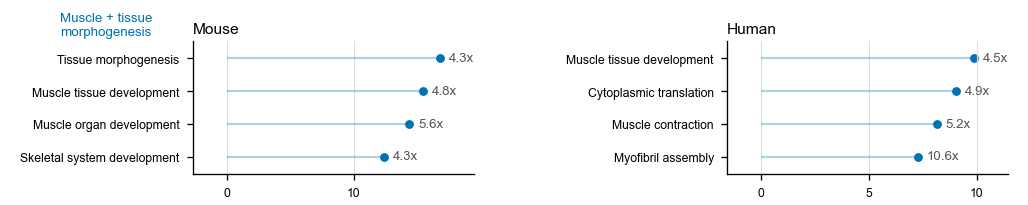

Cluster-GO row: Axon + tissue development


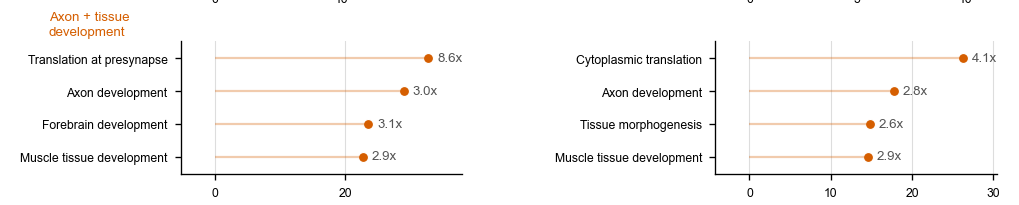

Cluster-GO row: Neural junctions + bioenergetics


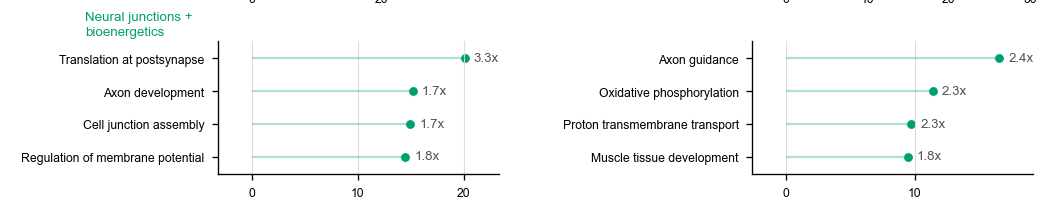

Cluster-GO row: Chromosome segregation


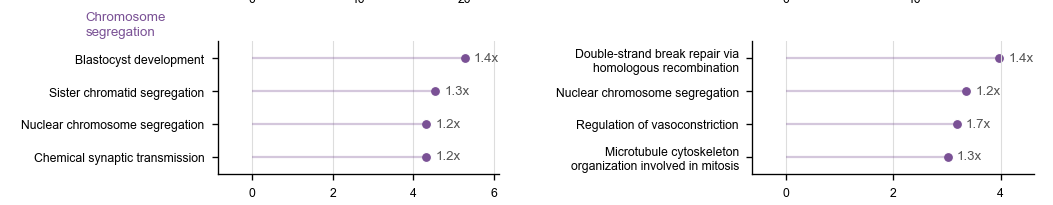

Cluster-GO row: Lipid + vesicle metabolism


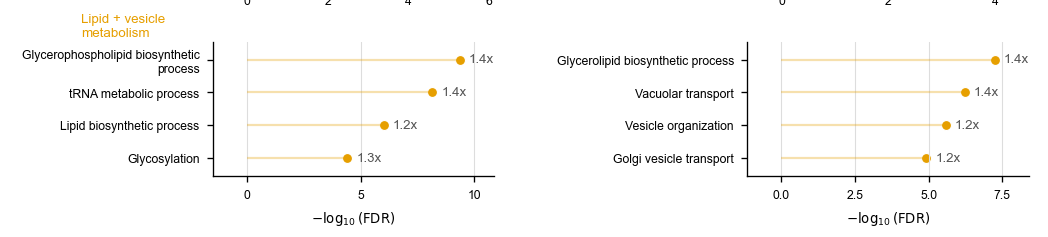

In [22]:
CLUSTER_GO_PREVIEW = build_cluster_go_figure()
for index, row in CENTRES.reset_index(drop=True).iterrows():
    preview_axes(
        CLUSTER_GO_PREVIEW,
        CLUSTER_GO_PREVIEW.axes[2 * index : 2 * index + 2],
        f"Cluster-GO row: {row.functional_label}",
    )
plt.close(CLUSTER_GO_PREVIEW)

### Save the combined cluster-GO supplement


In [23]:
figure = build_cluster_go_figure()
save_figure(figure, "cluster_go")
plt.close(figure)

wrote figures/embryo_xspecies/cluster_go.pdf


## Supplement: per-stage transition analysis

This analysis aims to gene-level changes (normalized expression, noise-adjusted
PCA movement, and SONIC DE, DF, and DF-norm tests) between consecutive developmental stages.

- Each species is analyzed over its own consecutive configured stages, with every
slide treated as a replicate. 
- Section counts (from earliest to latest stage): 
  - Mouse: 4/4/6/4/7/5.
  - Human: 4/4/4/4/4/4/4. Human CS17 and CS18 each represent one embryo.
- Mouse embryonic days are later mapped to a continuous Carnegie-stage axis only for visualization.

In [24]:
STAGE_PROGRAM_COLORS = {
    "mouse": PAPER_COLORS["warm"],
    "human": PAPER_COLORS["cool"],
}
TEST_STYLES = {
    "DE": ("fraction_de_significant", "-", "o"),
    "DF": ("fraction_df_significant", "--", "s"),
    "DF-norm": ("fraction_df_norm_significant", ":", "^"),
}

### Panels A-C: species-specific transition effects on a continuous CS axis

In [25]:
def _transition_axis(summary: pd.DataFrame) -> tuple[tuple[float, float], np.ndarray]:
    minimum = float(summary["current_cs"].min())
    maximum = float(summary["current_cs"].max())
    limits = (np.floor(minimum) - 0.6, np.ceil(maximum) + 0.6)
    ticks = np.arange(2 * np.ceil(minimum / 2), maximum + 1, 2)
    return limits, ticks


def _effect_distribution(
    ax: plt.Axes,
    transitions: pd.DataFrame,
    transition_summary: pd.DataFrame,
    *,
    value_column: str,
    title: str,
    ylabel: str,
    log1p: bool = False,
) -> None:
    """Show all genes and the median of statistically supported genes."""
    offsets = {"mouse": -0.12, "human": 0.12}
    for species in ("mouse", "human"):
        species_summary = transition_summary[transition_summary["species"].eq(species)].sort_values(
            "current_cs"
        )
        for row in species_summary.itertuples(index=False):
            group = transitions[
                transitions["species"].eq(species)
                & transitions["current_stage"].eq(row.current_stage)
            ]
            values = group[value_column].to_numpy(float)
            values = np.log1p(values) if log1p else values
            position = float(row.current_cs) + offsets[species]
            violin = ax.violinplot(
                values,
                positions=[position],
                widths=0.34,
                showextrema=False,
                bw_method=0.22,
            )
            for body in violin["bodies"]:
                body.set_facecolor(STAGE_PROGRAM_COLORS[species])
                body.set_edgecolor("none")
                body.set_alpha(0.32)
            # Add median and interquartile range lines on top of the violin plot
            q25, median, q75 = np.quantile(values, [0.25, 0.5, 0.75])
            ax.vlines(
                position,
                q25,
                q75,
                color=STAGE_PROGRAM_COLORS[species],
                linewidth=1.8,
            )
            ax.scatter(
                position,
                median,
                s=10,
                color="white",
                edgecolor=STAGE_PROGRAM_COLORS[species],
                linewidth=0.7,
                zorder=3,
            )

    limits, ticks = _transition_axis(transition_summary)
    ax.set(
        xlabel="Transition endpoint (CS)",
        ylabel=ylabel,
        xlim=limits,
        xticks=ticks,
    )
    ax.set_title(title, loc="left", pad=2)
    gene_counts = transition_summary.groupby("species")["n_genes"].first().to_dict()
    ax.legend(
        handles=[
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                color=color,
                label=f"{species.capitalize()} (n={gene_counts[species]:,} genes)",
                markersize=4,
            )
            for species, color in STAGE_PROGRAM_COLORS.items()
        ],
        frameon=False,
        loc="upper right",
        handletextpad=0.25,
        labelspacing=0.2,
    )


def plot_transition_summary_panels(
    figure: plt.Figure,
    slot: Any,
    transitions: pd.DataFrame,
    transition_summary: pd.DataFrame,
) -> list[plt.Axes]:
    """Plot expression, pattern-movement, and test-burden summaries."""
    grid = slot.subgridspec(1, 3, width_ratios=[1, 1, 1], wspace=0.4)
    ax_expression, ax_movement, ax_tests = [
        figure.add_subplot(grid[0, column]) for column in range(3)
    ]
    # Total expression change
    _effect_distribution(
        ax_expression,
        transitions,
        transition_summary,
        value_column="absolute_normalized_expression_change",
        title="Global expression change",
        ylabel="Relative change magnitude",
    )
    # PCA-space movement
    _effect_distribution(
        ax_movement,
        transitions,
        transition_summary,
        value_column="adjusted_movement",
        title="Spatial-pattern movement",
        ylabel="Noise-adjusted change strength",
        log1p=True,
    )
    movement_ticks = np.array([0, 0.5, 1, 2, 4, 8, 16])
    ax_movement.set(
        yticks=np.log1p(movement_ticks),
        yticklabels=[f"{value:g}" for value in movement_ticks],
    )

    # FDR-significant gene fraction
    for species in ("mouse", "human"):
        group = transition_summary[transition_summary["species"].eq(species)].sort_values(
            "current_cs"
        )
        for test, (column, linestyle, marker) in TEST_STYLES.items():
            ax_tests.plot(
                group["current_cs"],
                100 * group[column],
                color=STAGE_PROGRAM_COLORS[species],
                linestyle=linestyle,
                marker=marker,
                markersize=3,
                linewidth=1,
                label=f"{species.capitalize()} {test}",
            )
    limits, ticks = _transition_axis(transition_summary)
    ax_tests.set(
        xlabel="Transition endpoint (CS)",
        ylabel=r"Genes with FDR $\leq 0.05$ (%)",
        xlim=limits,
        xticks=ticks,
        ylim=(0, 100),
    )
    ax_tests.set_title("FDR-significant events", loc="left", pad=2)
    ax_tests.legend(
        frameon=False,
        ncol=2,
        loc="upper left",
        handlelength=1.7,
        handletextpad=0.35,
        columnspacing=0.7,
        labelspacing=0.2,
    )
    return [ax_expression, ax_movement, ax_tests]

Stage-transition panels A-C


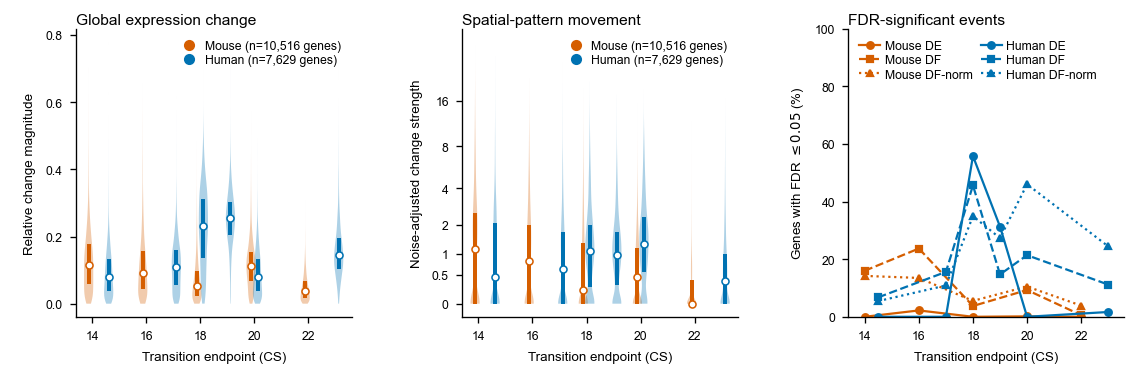

In [26]:
with plt.rc_context(FIGURE_STYLE):
    transition_summary_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 2.4))
    preview_slot = transition_summary_preview.add_gridspec(
        1, 1, left=0.05, right=0.95, bottom=0.20, top=0.95
    )[0]
    transition_summary_axes = plot_transition_summary_panels(
        transition_summary_preview,
        preview_slot,
        STAGE_TRANSITIONS,
        STAGE_TRANSITION_SUMMARY,
    )
preview_axes(
    transition_summary_preview,
    transition_summary_axes,
    "Stage-transition panels A-C",
)
plt.close(transition_summary_preview)

### Panels D-E: GO programs and stage-peaking gene examples

The GO panel shows six recurrent terms and six FDR-ranked stage-specific terms whose peaks are significant in at most half of one species'
transitions.

In [27]:
# To qualify as stage-specific, a term must be supported by no more than this fraction of transitions.
STAGE_PEAK_MAX_SUPPORT_FRACTION = 0.5


def _hybrid_program_terms(
    enrichment: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Select recurrent terms and terms concentrated around specific stages."""
    species = enrichment["query_group"].str.split("|").str[0]
    transitions_per_species = (
        enrichment.assign(species=species).groupby("species")["query_group"].nunique()
    )

    # Keep only terms that are significant, not too broad, and semantically simplified.
    eligible = enrichment.assign(
        species=species,
        strength=-np.log10(enrichment["p_adjust"].clip(lower=1e-300)),
        term_universe_fraction=(enrichment["term_size"] / enrichment["effective_domain_size"]),
    )
    eligible = eligible[
        eligible["p_adjust"].le(C.GO_FDR_THRESHOLD)
        & eligible["term_universe_fraction"].le(C.GO_MAX_TERM_UNIVERSE_FRACTION)
        & eligible["semantic_simplified"]
    ].reset_index(drop=True)

    keys = ["native", "display_name"]  # GO term ID and name

    # Record how broadly each term is supported within each species.
    eligible["species_support"] = eligible.groupby(keys + ["species"])["query_group"].transform(
        "nunique"
    )

    # Use each term's strongest transition to define its peak stage and species.
    peak_rows = eligible.loc[
        eligible.groupby(keys)["strength"].idxmax(),
        keys
        + [
            "query_group",
            "species",
            "strength",
            "species_support",
        ],
    ].rename(
        columns={
            "query_group": "peak_query",
            "species": "peak_species",
            "strength": "peak_score",
        }
    )

    terms = (
        eligible.groupby(keys, as_index=False)
        .agg(
            support=("query_group", "nunique"),
            mean_strength=("strength", "mean"),
        )
        .merge(peak_rows, on=keys, validate="one_to_one")
    )
    terms["species_support_fraction"] = terms["species_support"] / terms["peak_species"].map(
        transitions_per_species
    )

    # Recurrent terms: broadly supported, then ranked by average significance.
    recurrent = (
        terms[terms["support"].ge(STAGE_PEAK_MAX_SUPPORT_FRACTION * transitions_per_species.max())]
        .sort_values(
            ["support", "mean_strength"],
            ascending=[False, False],
        )
        .head(6)
        .assign(selection_group="recurrent")
    )

    # Stage-peaking terms: restricted to at most half of one species' transitions.
    stage_peaking = (
        terms[
            ~terms["native"].isin(recurrent["native"])
            & terms["species_support_fraction"].le(STAGE_PEAK_MAX_SUPPORT_FRACTION)
        ]
        .sort_values("peak_score", ascending=False)
        .drop_duplicates("peak_query")  # Strongest term for each transition.
        .groupby("peak_species", sort=False)
        .head(3)
        .assign(selection_group="stage-peaking")
    )

    selected = pd.concat([recurrent, stage_peaking], ignore_index=True)
    selected_rows = eligible[eligible["native"].isin(selected["native"])].drop(
        columns="species_support"
    )

    return selected_rows, selected


# Select one representative from each displayed stage-peaking program.
_, transition_terms = _hybrid_program_terms(STAGE_TRANSITION_ENRICHMENT)
program_names = [
    "Striated muscle tissue development",
    "Heart development",
    "Blood circulation",
]
fixed_program_genes = {
    "Heart development": "TNNT2",
    "Blood circulation": "CXCL12",
}
program_examples = []
for program_name in program_names:
    terms = transition_terms[
        transition_terms["selection_group"].eq("stage-peaking")
        & transition_terms["display_name"].eq(program_name)
    ]
    if len(terms) != 1:
        raise RuntimeError(f"Expected one displayed stage-peaking {program_name} term.")
    term = terms.iloc[0]
    enrichment = STAGE_TRANSITION_ENRICHMENT[
        STAGE_TRANSITION_ENRICHMENT["query_group"].eq(term["peak_query"])
        & STAGE_TRANSITION_ENRICHMENT["native"].eq(term["native"])
    ]
    if len(enrichment) != 1:
        raise RuntimeError(f"Expected one enrichment row for {program_name}.")
    hits = str(enrichment.iloc[0]["hit_genes"]).split("/")
    peak_species, peak_stage = str(term["peak_query"]).split("|")
    statistics = STAGE_TRANSITIONS[
        STAGE_TRANSITIONS["species"].eq(peak_species)
        & STAGE_TRANSITIONS["current_stage"].eq(peak_stage)
        & STAGE_TRANSITIONS["gene"].isin(hits)
    ].sort_values("df_norm_statistic", ascending=False)
    if program_name in fixed_program_genes:
        statistics = statistics[statistics["gene"].eq(fixed_program_genes[program_name])]
    if statistics.empty:
        raise RuntimeError(f"No representative gene found for {program_name}.")
    gene = str(statistics.iloc[0]["gene"])
    ortholog = POINTS.loc[
        POINTS["species"].eq(peak_species) & POINTS["gene"].eq(gene),
        ["mouse_symbol", "human_symbol"],
    ].drop_duplicates()
    if len(ortholog) != 1:
        raise RuntimeError(f"Expected one ortholog pair for {gene}.")
    program_examples.append(
        {
            **ortholog.iloc[0].to_dict(),
            "pathway_terms": program_name,
        }
    )
PROGRAM_GENES = pd.DataFrame(program_examples)
PROGRAM_SPATIAL_MAPS = _load_stage_spatial_maps(PROGRAM_GENES)
print(
    "stage-peaking spatial examples:",
    ", ".join(
        f"{row.mouse_symbol}/{row.human_symbol} ({row.pathway_terms})"
        for row in PROGRAM_GENES.itertuples(index=False)
    ),
)

stage-peaking spatial examples: Ankrd1/ANKRD1 (Striated muscle tissue development), Tnnt2/TNNT2 (Heart development), Cxcl12/CXCL12 (Blood circulation)


In [28]:
def plot_transition_go_panel(
    figure: plt.Figure,
    slot: Any,
    enrichment: pd.DataFrame,
    transition_summary: pd.DataFrame,
) -> list[plt.Axes]:
    """Plot recurrent and stage-peaking DF-norm GO programs."""
    # Select terms that are either recurrent or stage-peaking, and order them for plotting.
    eligible, selected = _hybrid_program_terms(enrichment)
    ordered = pd.concat(
        [
            transition_summary[transition_summary["species"].eq(species)].sort_values("current_cs")
            for species in ("mouse", "human")
        ],
        ignore_index=True,
    )
    query_order = [f"{row.species}|{row.current_stage}" for row in ordered.itertuples(index=False)]
    query_to_x = {query: index for index, query in enumerate(query_order)}
    query_sizes = enrichment.groupby("query_group")["query_size"].first()
    selected["peak_x"] = selected["peak_query"].map(query_to_x)
    stage_peaking = selected[selected["selection_group"].eq("stage-peaking")].sort_values(
        ["peak_x", "peak_score"], ascending=[False, True]
    )
    recurrent = selected[selected["selection_group"].eq("recurrent")].sort_values(
        "mean_strength", ascending=False
    )

    # Prepare a bubble chart of the selected terms, with x-axis as query groups and y-axis as GO terms.
    selected = pd.concat([stage_peaking, recurrent], ignore_index=True)
    term_to_y = {term: index for index, term in enumerate(selected["native"])}
    bubbles = eligible[
        eligible["native"].isin(term_to_y) & eligible["query_group"].isin(query_to_x)
    ].copy()
    bubbles["x"] = bubbles["query_group"].map(query_to_x)
    bubbles["y"] = bubbles["native"].map(term_to_y)
    bubbles["strength"] = -np.log10(np.maximum(bubbles["p_adjust"], 1e-300))

    # Plot GO terms as a bubble chart
    grid = slot.subgridspec(1, 4, width_ratios=[0.15, 0.70, 0.02, 0.08], wspace=0.1)
    ax_program = figure.add_subplot(grid[0, 1])
    cax = figure.add_subplot(grid[0, 2])
    legend_ax = figure.add_subplot(grid[0, 3])
    legend_ax.axis("off")
    image = ax_program.scatter(
        bubbles["x"],
        bubbles["y"],
        s=5 + 0.75 * bubbles["intersection_size"],
        c=bubbles["strength"],
        cmap="cividis",
        vmin=-np.log10(C.GO_FDR_THRESHOLD),
        vmax=float(min(25, bubbles["strength"].quantile(0.95))),
        edgecolor="white",
        linewidth=0.35,
        zorder=5,
    )
    ax_program.set(
        xticks=np.arange(len(query_order)),
        xticklabels=[
            (
                f"{row.current_stage}\nCS{row.current_cs:g} (M)\nn={int(query_sizes.loc[query]):,}"
                if row.species == "mouse"
                else f"{row.current_stage}\n(H)\nn={int(query_sizes.loc[query]):,}"
            )
            for row, query in zip(ordered.itertuples(index=False), query_order, strict=True)
        ],
        yticks=np.arange(len(selected)),
        yticklabels=[
            textwrap.fill(name, width=34, break_long_words=False)
            for name in selected["display_name"]
        ],
    )
    ax_program.set_title(
        "Recurrent (top) and stage-peaking (bottom) GO programs",
        loc="left",
        pad=2,
    )
    mouse_transitions = int(ordered["species"].eq("mouse").sum())
    ax_program.axvline(mouse_transitions - 0.5, color="#cccccc", linewidth=0.8)
    ax_program.axhline(len(stage_peaking) - 0.5, color="#cccccc", linewidth=0.8)
    ax_program.grid(color="#eeeeee", linewidth=0.35)

    colorbar = figure.colorbar(image, cax=cax)
    colorbar.set_label(r"$-\log_{10}(\mathrm{FDR})$", fontsize=FONT_TEXT, labelpad=2)
    colorbar.ax.tick_params(labelsize=FONT_MIN, width=0.4, length=2)
    size_handles = [
        ax_program.scatter([], [], s=5 + 0.75 * size, color="#777777", label=str(size))
        for size in (20, 50)
    ]
    legend_ax.legend(
        handles=size_handles,
        title="Intersection w/\nDF-norm genes",
        title_fontsize=FONT_TEXT,
        frameon=False,
        loc="upper left",
        borderaxespad=0,
        handletextpad=0.3,
        # labelspacing=0.4,
    )
    return [ax_program, cax, legend_ax]

Stage-transition panel D


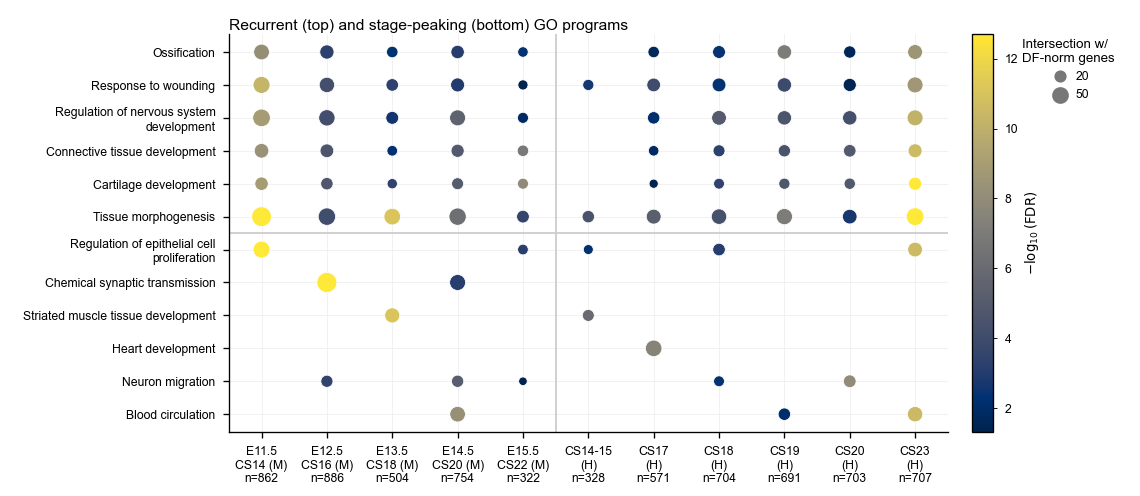

In [29]:
with plt.rc_context(FIGURE_STYLE):
    transition_go_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 3.0))
    preview_slot = transition_go_preview.add_gridspec(
        1, 1, left=0.05, right=0.95, bottom=0.12, top=0.95
    )[0]
    transition_go_axes = plot_transition_go_panel(
        transition_go_preview,
        preview_slot,
        STAGE_TRANSITION_ENRICHMENT,
        STAGE_TRANSITION_SUMMARY,
    )
preview_axes(
    transition_go_preview,
    transition_go_axes,
    "Stage-transition panel D",
)
plt.close(transition_go_preview)

Stage-transition panel E


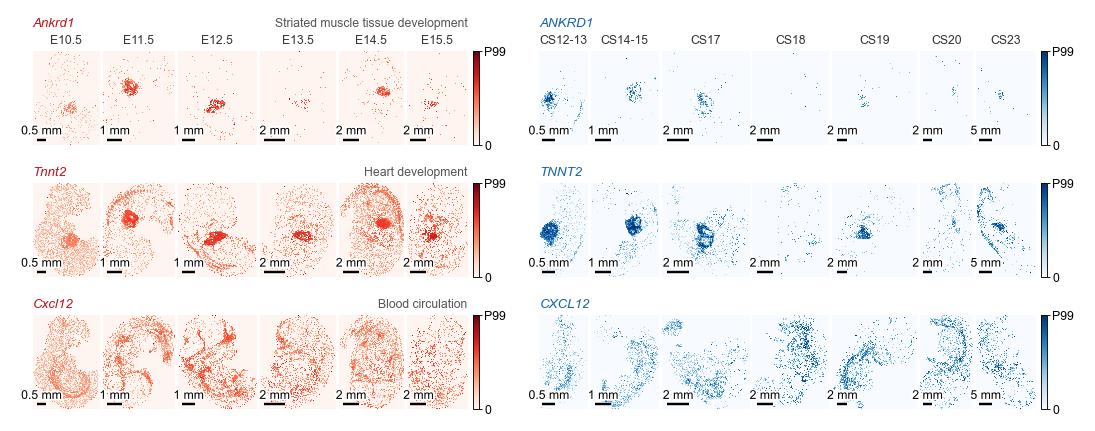

In [30]:
with plt.rc_context(FIGURE_STYLE):
    transition_program_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 3.25))
    preview_slot = transition_program_preview.add_gridspec(
        1, 1, left=0.08, right=0.95, bottom=0.08, top=0.82
    )[0]
    transition_program_axes = plot_spatial_gene_rows(
        transition_program_preview, preview_slot, PROGRAM_GENES, PROGRAM_SPATIAL_MAPS
    )
preview_axes(
    transition_program_preview,
    transition_program_axes,
    "Stage-transition panel E",
)
plt.close(transition_program_preview)

### Save the species-specific transition supplement


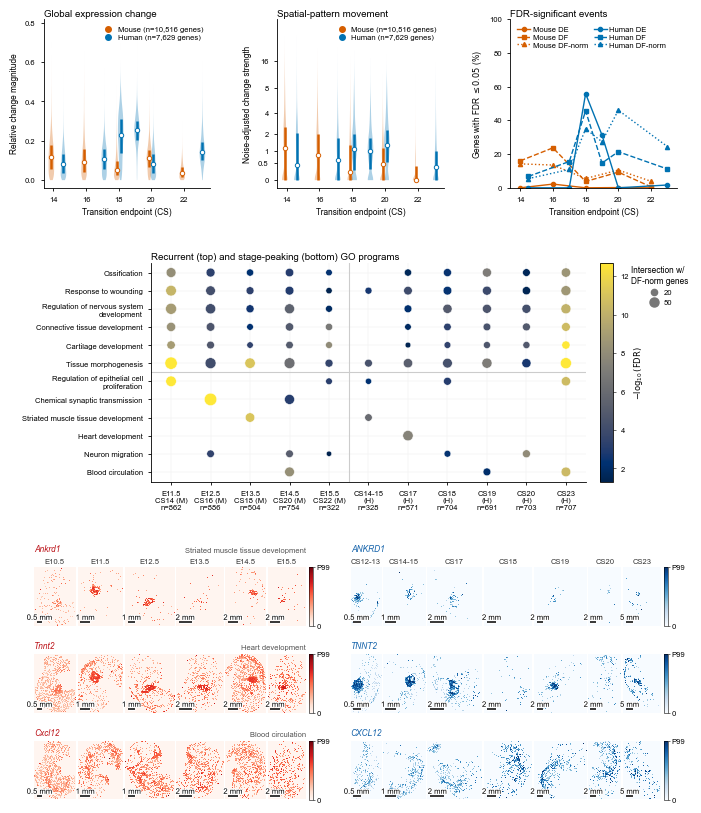

In [31]:
def build_stage_transition_figure() -> plt.Figure:
    """Assemble transition summaries, GO programs, and gene examples."""
    with plt.rc_context(FIGURE_STYLE):
        figure = plt.figure(figsize=(FIGURE_WIDTH_IN, 8.5))
        rows = figure.add_gridspec(
            3,
            1,
            left=0.08,
            right=0.95,
            bottom=0.04,
            top=0.97,
            height_ratios=[1, 1.3, 1.5],
            hspace=0.35,
        )
        plot_transition_summary_panels(figure, rows[0], STAGE_TRANSITIONS, STAGE_TRANSITION_SUMMARY)
        plot_transition_go_panel(
            figure,
            rows[1],
            STAGE_TRANSITION_ENRICHMENT,
            STAGE_TRANSITION_SUMMARY,
        )
        plot_spatial_gene_rows(figure, rows[2], PROGRAM_GENES, PROGRAM_SPATIAL_MAPS)
        return figure


build_stage_transition_figure()

In [32]:
figure = build_stage_transition_figure()
save_figure(figure, "stage_transitions")
plt.close(figure)

wrote figures/embryo_xspecies/stage_transitions.pdf


## Supplement: temporal variation

In [33]:
SELECTED_SPATIAL_MAPS = _load_stage_spatial_maps(SELECTED_GENES)

### Panels A–C: species-specific variation and ortholog conservation


In [34]:
def _plot_variance_panel(
    ax: plt.Axes,
    metrics: pd.DataFrame,
    selected: pd.DataFrame,
    species: str,
) -> None:
    within = metrics["within_stage_variance"].to_numpy(float)
    between = metrics["between_stage_variance"].to_numpy(float)
    positive = np.concatenate([within[within > 0], between[between > 0]])
    floor = float(np.quantile(np.log10(positive), 0.01) - 0.2)
    x = np.where(within > 0, np.log10(np.maximum(within, 1e-300)), floor)
    y = np.where(between > 0, np.log10(np.maximum(between, 1e-300)), floor)
    x_padding = 0.04 * (x.max() - x.min())
    y_padding = 0.04 * (y.max() - y.min())
    x_limits = (x.min() - x_padding, x.max() + x_padding)
    y_limits = (y.min() - y_padding, y.max() + y_padding)

    # Genes with within-stage variance in the top 5% are considered outliers and are plotted in gray.
    passing = metrics["passes_within_stage_filter"].to_numpy(bool)
    ax.scatter(
        x[~passing],
        y[~passing],
        s=SCATTER_POINT_SIZE,
        color="#bdbdbd",
        alpha=0.1,
        linewidth=0,
        rasterized=True,
    )
    ax.scatter(
        x[passing],
        y[passing],
        s=SCATTER_POINT_SIZE,
        color="#333333",
        alpha=0.05,
        linewidth=0,
        rasterized=True,
    )
    cutoff = float(np.log10(metrics.loc[passing, "within_stage_variance"].max()))
    ax.axvspan(cutoff, x_limits[1], color="#eeeeee", alpha=0.50, zorder=-2)
    ax.axvline(cutoff, color="#666666", linestyle=":", linewidth=0.8)
    diagonal_low = max(x_limits[0], y_limits[0])
    diagonal_high = min(x_limits[1], y_limits[1])
    ax.plot(
        [diagonal_low, diagonal_high],
        [diagonal_low, diagonal_high],
        color="#777777",
        linestyle="-",
        linewidth=0.7,
        zorder=0,
    )
    ax.legend(
        handles=[
            Line2D([], [], color="#777777", linestyle="-", linewidth=0.8, label="x = y"),
            Line2D(
                [],
                [],
                color="#666666",
                linestyle=":",
                linewidth=0.8,
                label="High within-stage var cutoff",
            ),
        ],
        loc="lower right",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=0.8,
        borderpad=0.25,
        handlelength=1.5,
        handletextpad=0.4,
        labelspacing=0.2,
    )

    # Highlight selected genes
    symbol_column = f"{species}_symbol"
    labels = []
    label_x = []
    label_y = []
    for row in selected.itertuples():
        symbol = str(getattr(row, symbol_column))
        match = metrics[metrics["gene"].eq(symbol)]
        if match.empty:
            continue
        point = match.iloc[0]
        point_x = (
            np.log10(point["within_stage_variance"])
            if point["within_stage_variance"] > 0
            else floor
        )
        point_y = (
            np.log10(point["between_stage_variance"])
            if point["between_stage_variance"] > 0
            else floor
        )
        ax.scatter(
            point_x,
            point_y,
            s=24,
            color=CATEGORY_COLORS[row.category],
            edgecolor="white",
            linewidth=0.7,
            zorder=4,
        )
        annotation = ax.text(
            point_x,
            point_y,
            symbol,
            fontsize=FONT_TITLE,
            fontstyle="italic",
            color=CATEGORY_COLORS[row.category],
            zorder=5,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1},
        )
        labels.append(annotation)
        label_x.append(point_x)
        label_y.append(point_y)
    adjust_text(
        labels,
        ax=ax,
        x=label_x,
        y=label_y,
        force_text=(1, 1),
        expand=(1.35, 1.5),
        # arrowprops={"arrowstyle": "-", "color": "#777777", "lw": 0.5},
    )
    ax.set(
        xlabel="Within-stage variance (log10)",
        ylabel="Between-stage variance (log10)",
        xlim=x_limits,
        ylim=y_limits,
    )
    ax.set_title(f"{species.capitalize()} stage variation", loc="left", y=1.02, pad=2)


def plot_temporal_variation_panels(
    figure: plt.Figure,
    slot: Any,
    mouse: pd.DataFrame,
    human: pd.DataFrame,
    conservation: pd.DataFrame,
    conservation_summary: dict[str, float],
    selected: pd.DataFrame,
) -> list[plt.Axes]:
    """Plot species-specific variance and ortholog conservation."""
    grid = slot.subgridspec(1, 3, wspace=0.4)
    ax_mouse, ax_human, ax_conservation = [
        figure.add_subplot(grid[0, column]) for column in range(3)
    ]
    # Plot within- and between-stage variance for mouse and human.
    _plot_variance_panel(ax_mouse, mouse, selected, "mouse")
    _plot_variance_panel(ax_human, human, selected, "human")

    # Plot ortholog conservation as a scatter plot of mouse vs human dynamic percentiles.
    ax = ax_conservation
    background = conservation[conservation["dynamic_group"].eq("not top-decile")]
    ax.scatter(
        background["mouse_dynamic_percentile"],
        background["human_dynamic_percentile"],
        s=SCATTER_POINT_SIZE,
        color="#333333",
        alpha=0.04,
        linewidth=0,
        rasterized=True,
        zorder=0,
    )
    displayed_groups = [
        "mouse-specific dynamic",
        "human-specific dynamic",
        "conserved dynamic",
    ]
    for group in displayed_groups:
        subset = conservation[conservation["dynamic_group"].eq(group)]
        ax.scatter(
            subset["mouse_dynamic_percentile"],
            subset["human_dynamic_percentile"],
            s=SCATTER_POINT_SIZE + 1,
            color=CATEGORY_COLORS[group],
            alpha=0.25,
            linewidth=0,
            rasterized=True,
            label=f"{group.removesuffix(' dynamic').capitalize()} (n={len(subset)})",
            zorder=1,
        )
    ax.axvline(
        C.TEMPORAL_DYNAMIC_PERCENTILE_THRESHOLD,
        color="#777777",
        linestyle=":",
        linewidth=0.8,
    )
    ax.axhline(
        C.TEMPORAL_DYNAMIC_PERCENTILE_THRESHOLD,
        color="#777777",
        linestyle=":",
        linewidth=0.8,
    )
    conservation_labels = []
    conservation_x = []
    conservation_y = []
    for row in selected.itertuples():
        ax.scatter(
            row.mouse_dynamic_percentile,
            row.human_dynamic_percentile,
            s=24,
            color=CATEGORY_COLORS[row.category],
            edgecolor="white",
            linewidth=0.7,
            zorder=3,
        )
        annotation = ax.text(
            row.mouse_dynamic_percentile,
            row.human_dynamic_percentile,
            row.mouse_symbol,
            fontsize=FONT_TITLE,
            fontstyle="italic",
            color=CATEGORY_COLORS[row.category],
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1},
        )
        conservation_labels.append(annotation)
        conservation_x.append(row.mouse_dynamic_percentile)
        conservation_y.append(row.human_dynamic_percentile)
    adjust_text(
        conservation_labels,
        ax=ax,
        x=conservation_x,
        y=conservation_y,
        expand=(1.35, 1.5),
        force_text=(1, 1),
        # arrowprops={"arrowstyle": "-", "color": "#777777", "lw": 0.5},
    )
    legend = ax.legend(
        frameon=False,
        loc="lower left",
        borderaxespad=0.25,
        handletextpad=0.25,
        markerscale=1.5,
    )
    # Reset legend handle alpha to 1.0 for better visibility
    for handle in legend.legend_handles:
        handle.set_alpha(1.0)

    ax.set(
        xlabel="Mouse variation percentile",
        ylabel="Human variation percentile",
        xlim=(-0.02, 1.10),
        ylim=(-0.02, 1.12),
        xticks=[0, 0.5, 1],
        yticks=[0, 0.5, 1],
    )
    ax.set_title(
        "Ortholog temporal variation\n"
        f"joint top decile: {conservation_summary['top_decile_fold_enrichment']:.1f}x expected",
        loc="left",
        pad=2,
        y=1.02,
    )
    return [ax_mouse, ax_human, ax_conservation]

Temporal-variation panels A-C


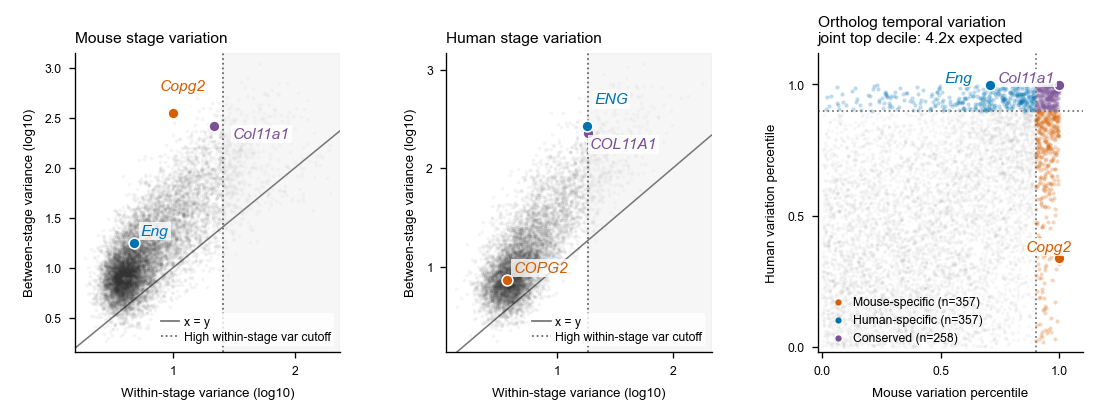

In [35]:
with plt.rc_context(FIGURE_STYLE):
    temporal_variation_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 2.4))
    preview_slot = temporal_variation_preview.add_gridspec(
        1, 1, left=0.12, right=0.985, bottom=0.18, top=0.96
    )[0]
    temporal_variation_axes = plot_temporal_variation_panels(
        temporal_variation_preview,
        preview_slot,
        MOUSE_TEMPORAL,
        HUMAN_TEMPORAL,
        ORTHOLOG_TEMPORAL,
        TEMPORAL_MANIFEST,
        SELECTED_GENES,
    )
preview_axes(
    temporal_variation_preview,
    temporal_variation_axes,
    "Temporal-variation panels A-C",
)
plt.close(temporal_variation_preview)

### Panel D: GO programs


In [36]:
def _plot_temporal_go_axis(
    ax: plt.Axes,
    terms: pd.DataFrame,
    group: str,
) -> None:
    """Plot one mutually exclusive temporal-dynamics GO set."""
    group_terms = terms[terms["query_group"].eq(group)].sort_values("p_adjust", ascending=False)
    y = np.arange(len(group_terms))
    strength = -np.log10(np.maximum(group_terms["p_adjust"], 1e-300))
    # Compute fold enrichment against expected overlap size
    fold = group_terms["intersection_size"] / (
        group_terms["query_size"] * group_terms["term_size"] / group_terms["effective_domain_size"]
    )
    color = CATEGORY_COLORS[group]
    ax.hlines(y, 0, strength, color=color, alpha=0.32, linewidth=1)
    ax.scatter(
        strength,
        y,
        s=20,
        color=color,
        edgecolor="white",
        linewidth=0.5,
    )
    for x_value, y_value, enrichment in zip(strength, y, fold, strict=True):
        ax.annotate(
            f"{enrichment:.1f}x",
            (x_value, y_value),
            xytext=(4, 0),
            textcoords="offset points",
            fontsize=FONT_TEXT,
            va="center",
            color="#555555",
        )
    ax.set(
        xlabel=r"$-\log_{10}(\mathrm{FDR})$",
        yticks=y,
        yticklabels=[
            textwrap.fill(name, width=25, break_long_words=False)
            for name in group_terms["display_name"]
        ],
    )
    ax.margins(x=0.16, y=0.18)
    ax.grid(axis="x", color="#dddddd", linewidth=0.5)
    ax.set_title(group.capitalize(), loc="left", pad=2, color=color, y=1.02)


def plot_temporal_go_panel(
    figure: plt.Figure,
    slot: Any,
    terms: pd.DataFrame,
) -> list[plt.Axes]:
    """Plot the two temporal-dynamics GO sets as matched lollipops."""
    groups = terms["query_group"].drop_duplicates().tolist()
    grid = slot.subgridspec(1, 2, wspace=0.5)
    axes = [figure.add_subplot(grid[0, column]) for column in range(2)]
    for ax, group in zip(axes, groups, strict=True):
        _plot_temporal_go_axis(ax, terms, group)
    return axes

Temporal-variation panel D


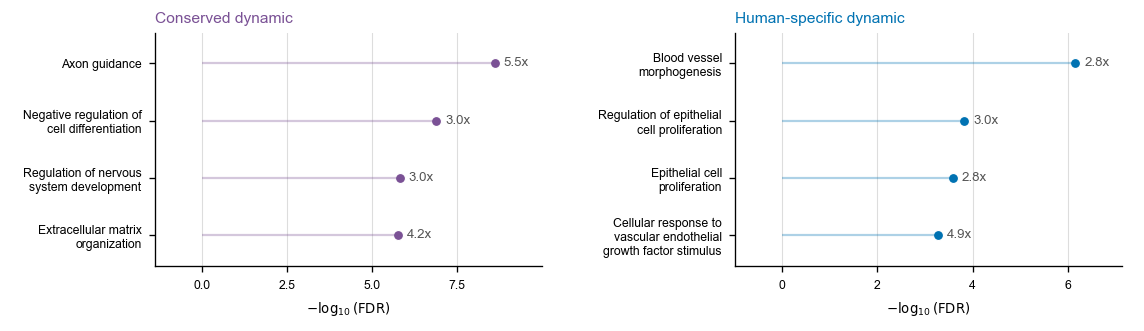

In [37]:
with plt.rc_context(FIGURE_STYLE):
    temporal_go_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 2))
    preview_slot = temporal_go_preview.add_gridspec(
        1, 1, left=0.13, right=0.96, bottom=0.20, top=0.93
    )[0]
    temporal_go_axes = plot_temporal_go_panel(temporal_go_preview, preview_slot, TEMPORAL_TERMS)
preview_axes(temporal_go_preview, temporal_go_axes, "Temporal-variation panel D")
plt.close(temporal_go_preview)

### Panel E: selected-gene spatial dynamics and PCA trajectories


In [38]:
def plot_selected_gene_dynamics_panel(  # noqa: C901
    figure: plt.Figure,
    slot: Any,
    selected: pd.DataFrame,
    profiles: pd.DataFrame,
    spatial_maps: list[dict[str, Any]],
) -> None:
    """Plot trajectories above full-width mouse/human spatial stage series."""
    spatial_cmaps = {
        "mouse": plt.get_cmap("Reds"),
        "human": plt.get_cmap("Blues"),
    }
    trajectory_points = profiles[profiles["mouse_symbol"].isin(selected["mouse_symbol"])][
        ["PC1", "PC2"]
    ]
    trajectory_limits = {}
    for column in ("PC1", "PC2"):
        low, high = trajectory_points[column].agg(["min", "max"])
        padding = 0.08 * max(high - low, 1e-6)
        trajectory_limits[column] = (low - padding, high + padding)

    # First row shows trajectories of selected genes in PCA space;
    # Second row shows spatial maps for each gene across stages.
    outer = slot.subgridspec(2, 1, height_ratios=[0.6, 1.6], hspace=0.25)
    # Within the first row, the upper subgrid holds a title and legend,
    upper = outer[0, 0].subgridspec(2, 1, height_ratios=[0.12, 0.64], hspace=0.12)
    header = figure.add_subplot(upper[0, 0])
    header.axis("off")
    header.text(0, 0.72, "Selected gene dynamics", fontsize=FONT_TITLE, va="center")
    header.legend(
        handles=[
            Line2D(
                [],
                [],
                color=spatial_cmaps["mouse"](0.75),
                marker="o",
                label="Mouse",
            ),
            Line2D(
                [],
                [],
                color=spatial_cmaps["human"](0.75),
                marker="^",
                linestyle="--",
                label="Human",
            ),
            Line2D(
                [],
                [],
                color="#777777",
                linewidth=1.4,
                label="Trajectory color: early (light) to late (dark) stages",
            ),
        ],
        frameon=False,
        loc="upper right",
        borderaxespad=0,
        handletextpad=0.4,
        columnspacing=0.8,
        ncol=3,
    )

    # Per-gene trajectory plots are arranged in a single row, one column per gene.
    trajectory_grid = upper[1, 0].subgridspec(1, len(selected), wspace=0.3)
    for column_index, candidate in enumerate(selected.itertuples()):
        trajectory_ax = figure.add_subplot(trajectory_grid[0, column_index])
        gene_profiles = profiles[profiles["mouse_symbol"].eq(candidate.mouse_symbol)]
        for species, group in gene_profiles.groupby("species", sort=False):
            group = group.sort_values("stage_index")
            cmap = spatial_cmaps[species]
            progress = np.linspace(0.45, 0.9, len(group))
            coordinates = group[["PC1", "PC2"]].to_numpy(float)
            for segment_index in range(len(group) - 1):
                trajectory_ax.plot(
                    coordinates[segment_index : segment_index + 2, 0],
                    coordinates[segment_index : segment_index + 2, 1],
                    color=cmap(progress[segment_index + 1]),
                    linestyle="-" if species == "mouse" else "--",
                    linewidth=1.4,
                )
            trajectory_ax.scatter(
                group["PC1"],
                group["PC2"],
                c=cmap(progress),
                marker="o" if species == "mouse" else "^",
                s=18,
                edgecolor="white",
                linewidth=0.5,
                zorder=3,
            )
        trajectory_ax.set(
            xlim=trajectory_limits["PC1"],
            ylim=trajectory_limits["PC2"],
            xlabel="PC1",
            ylabel="PC2" if column_index == 0 else "",
        )
        if column_index:
            trajectory_ax.tick_params(labelleft=False)
        trajectory_ax.tick_params(labelsize=FONT_TICK, pad=1)
        trajectory_ax.set_title(
            (
                rf"$\mathit{{{candidate.mouse_symbol}}}$ / "
                rf"$\mathit{{{candidate.human_symbol}}}$ "
                f"({candidate.category.removesuffix(' dynamic')})"
            ),
            loc="center",
            y=0.97,
            pad=2,
            fontsize=FONT_LABEL,
            color=CATEGORY_COLORS[candidate.category],
            linespacing=1.25,
        )

    plot_spatial_gene_rows(figure, outer[1, 0], selected, spatial_maps)

Temporal-variation panel E


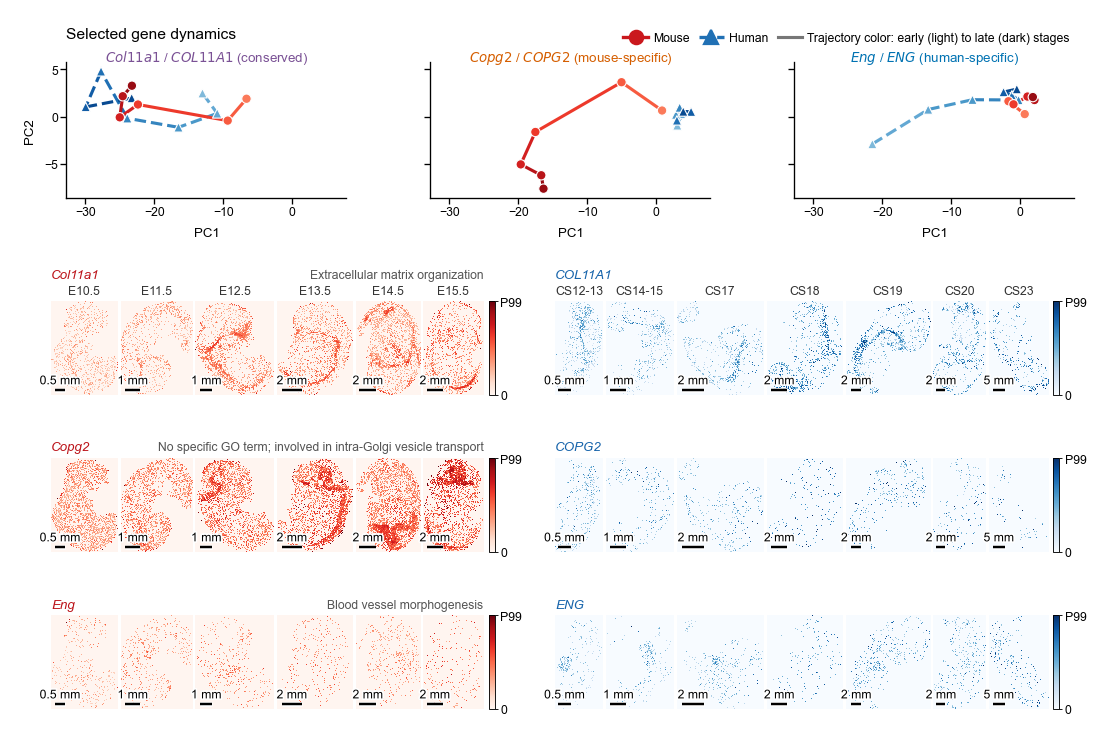

In [39]:
with plt.rc_context(FIGURE_STYLE):
    selected_gene_preview = plt.figure(figsize=(FIGURE_WIDTH_IN, 4.65))
    preview_slot = selected_gene_preview.add_gridspec(
        1, 1, left=0.12, right=0.985, bottom=0.03, top=0.98
    )[0]
    plot_selected_gene_dynamics_panel(
        selected_gene_preview,
        preview_slot,
        SELECTED_GENES,
        TRAJECTORIES,
        SELECTED_SPATIAL_MAPS,
    )
preview_axes(
    selected_gene_preview,
    selected_gene_preview.axes,
    "Temporal-variation panel E",
)
plt.close(selected_gene_preview)

### Save the combined temporal-variation supplement


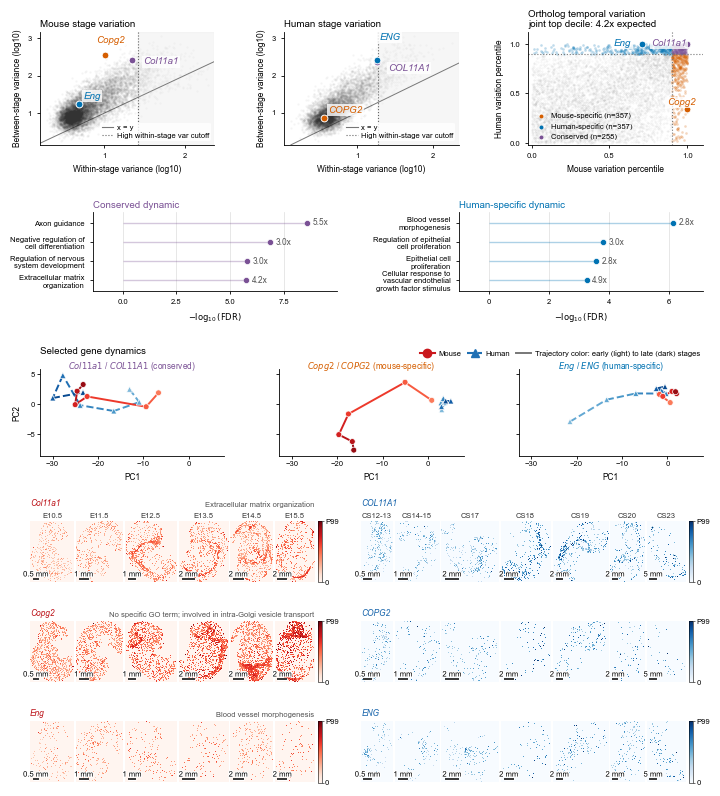

In [40]:
def build_temporal_variation_figure() -> plt.Figure:
    """Assemble temporal variation, GO programs, and selected-gene dynamics."""
    with plt.rc_context(FIGURE_STYLE):
        figure = plt.figure(figsize=(FIGURE_WIDTH_IN, 8.5), constrained_layout=False)
        rows = figure.add_gridspec(
            5,
            1,
            height_ratios=[0.5, 0.15, 0.35, 0.1, 2],
            left=0.075,
            right=0.985,
            bottom=0.05,
            top=0.95,
            hspace=0.12,
        )
        plot_temporal_variation_panels(
            figure,
            rows[0],
            MOUSE_TEMPORAL,
            HUMAN_TEMPORAL,
            ORTHOLOG_TEMPORAL,
            TEMPORAL_MANIFEST,
            SELECTED_GENES,
        )
        go_row = rows[2].subgridspec(1, 2, width_ratios=[0.08, 0.92], wspace=0)
        plot_temporal_go_panel(figure, go_row[0, 1], TEMPORAL_TERMS)
        plot_selected_gene_dynamics_panel(
            figure,
            rows[4],
            SELECTED_GENES,
            TRAJECTORIES,
            SELECTED_SPATIAL_MAPS,
        )
        return figure


build_temporal_variation_figure()

In [41]:
figure = build_temporal_variation_figure()
save_figure(figure, "temporal_variation")
plt.close(figure)

wrote figures/embryo_xspecies/temporal_variation.pdf
